# Práctica — Leyes de potencia y periodicidades en hipnogramas

**Licenciatura en Inteligencia Artificial**

Los archivos CSV que se comparten contienen hipnogramas de registros de aproximadamente **8 horas** de sueño. Cada fila corresponde a un **segmento de 30 segundos**. La primera columna es el número de segmento y la segunda es la etapa de sueño codificada de la siguiente manera:

| Código | Etapa |
|---|---|
| 0 | Vigilia (W) |
| 1 | Etapa 1 |
| 2 | Etapa 2 |
| 3 | Etapa 3 |
| 4 | Etapa 4 |
| 5 | REM (MOR) |
| 6 | Movimiento |
| 7 | Sin clasificar |

> **Tiempo-vida (lifetime):** duración de una racha consecutiva de un mismo símbolo. Por ejemplo, en la secuencia `... 2 2 2 5 ...` la etapa 2 tiene un tiempo-vida de 3 segmentos = 90 segundos. Todo el análisis de esta práctica se construye sobre esta magnitud.


## Objetivos

Al terminar esta práctica deberás ser capaz de:

1. Generar los gráficos **tiempo-vida de las fases de sueño vs. frecuencia** (en escala log-log) de cada hipnograma.
2. Estimar el exponente de la ley de potencia $\alpha$ mediante **regresión por mínimos cuadrados (OLS)** sobre el log-log (tiempo-vida vs. frecuencia), reportando **p-valor y $R^2$**; y contrastar con el **método de Clauset** (máxima verosimilitud + estimación de $x_{\min}$ + p-valor por Monte Carlo), usando el paquete `powerlaw`. Estimar el p-valor en ambos casos **e interpretarlo**.
3. Comparar ambos métodos y **justificar cuál es mejor**.
4. Repetir el análisis completo (puntos 1, 2 y 3) con **bigramas, trigramas, ..., 7-gramas**.
5. Concluir **qué $n$-grama se parece más a una ley de potencia**.
6. Elegir **una medida de teoría de la información** (entropía marginal, entropía conjunta, entropía condicional o información mutua, de manera univariada) para buscar **periodicidades** en la dinámica de cada registro.
7. Generar los gráficos de la medida elegida **en función del retardo $\tau$** e interpretar si existe evidencia de comportamiento periódico.


## 6. Teoría de la información: buscando periodicidades

**Elige UNA** de las siguientes medidas y justifica tu elección:

| Medida | Definición | Qué revela |
|---|---|---|
| Entropía marginal | $H(X) = -\sum_x p(x)\log_2 p(x)$ | Uniformidad del histograma de etapas |
| Entropía conjunta | $H(X_t, X_{t+\tau})$ | Incertidumbre conjunta a retardo $\tau$ |
| Entropía condicional | $H(X_{t+\tau}\mid X_t) = H(X_t,X_{t+\tau}) - H(X_t)$ | Incertidumbre residual del futuro dado el presente |
| Información mutua | $I(X_t;X_{t+\tau}) = H(X_t)+H(X_{t+\tau})-H(X_t,X_{t+\tau})$ | Redundancia compartida; **picos en los retardos periódicos** |

La idea: si la dinámica tiene un **período $T$**, muestrear la señal cada $\tau = T, 2T, \dots$ la alinea consigo misma. Esperamos entonces: **mínimos** en $H(\tau)$ (menor sorpresa) o **máximos** en $I(\tau)$ (máxima dependencia) en esos retardos. En el sueño, el candidato fisiológico es el **ciclo ultradiano de ~90 min ≈ 180 segmentos** (≈ 1.5 h).

## 7. Interpretación de los resultados

1. **Describe la forma de la curva**: ¿hay mínimos locales de la entropía (o máximos de la información mutua)? ¿En qué valores de $\tau$ aparecen?
2. **Relación con la fisiología**: ¿coinciden con el ciclo de ~90 min? ¿Se observan armónicos ($\tau \approx 3$ h)?
3. **Comparación entre registros**: ¿el patrón es consistente entre archivos?
4. **Artefactos**: discute el efecto de las etapas 6 (Movimiento) y 7 (Sin clasificar). Opcional: repite la figura **excluyéndolas** (reemplázalas o filtra la señal) y compara.
5. **Conclusión**: ¿hay evidencia estadística/estructural de comportamiento periódico en la dinámica univariada de los hipnogramas? Argumenta a favor o en contra, y conecta con lo encontrado en el punto 5 (¿cambia la respuesta con el $n$-grama elegido?).

---

## Entregables
- Notebook ejecutado (código + salidas) con las figuras de los puntos 1, 4 y 7.
- Tablas resumen de los puntos 2 y 4 (con **interpretación escrita** de p-valores y $R^2$).
- Discusión de los puntos 3, 5 y 7 en celdas markdown.



## Rúbrica TENTATIVA (100 pts)
| Criterio | Pts |
|---|---|
| Gráficos log-log correctos y completos (pts. 1) | 15 |
| Estimación e interpretación OLS + Clauset (pt. 2) | 25 |
| Comparación y justificación de métodos (pt. 3) | 15 |
| Análisis n-gramas + tabla + conclusión (pts. 4–5) | 20 |
| Medida de información, figuras e interpretación (pts. 6–7) | 15 |
| Calidad del notebook y del informe | 10 |

#Metodo Clauset, Shalitzi, Newman

### Descarga del Dataset desde Google Drive

Utilizamos la herramienta `gdown` para descargar el contenido de la carpeta compartida de Google Drive directamente en nuestro entorno de trabajo local.

In [1]:
import gdown

# URL de la carpeta compartida de Google Drive
folder_url = 'https://drive.google.com/drive/folders/1n1cFSSvTwxg5M1oJ-HYpzI89lMprNhDM?usp=drive_link'

# Descargamos los archivos de la carpeta compartida de Drive
# Usamos gdown con la opción --folder para descargar carpetas completas
try:
    gdown.download_folder(url=folder_url, remaining_ok=True, use_cookies=False)
except Exception as e:
    print(f"Ocurrió un error al descargar la carpeta: {e}")

Retrieving folder contents


Processing file 1xNj0MQ06JTGhzOkSXuqZLUUl_F3eeHmz Scoring_AA_1
Processing file 16_TjhOu5BUtHX2S-kQZ-P051132ugs1x Scoring_AG_1
Processing file 1LlgbRfjQDWzj7LNaApWNPMXutlycRVUd Scoring_AQ_1
Processing file 1qZCuugnzkC-vnquCmFC7uuHnhPrFu06- Scoring_AR_1
Processing file 1Am6JM8SvbbKaerIU7LYUc5LHX4hNSG0P Scoring_AR_2
Processing file 1T7pd6Cm7lvMxWz9138skYcIGqcmnIwsU Scoring_AV_1
Processing file 178kCLO7nKGCvJlnMYUwSUG-R09WtCPGA Scoring_BP_1
Processing file 1UYSFI8xqIvUiBXqZnxql-EUG3Vm8BexF Scoring_CG_i
Processing file 1ftp-WfQ9Aw5UIq76ZDN5tba3mmAAPUA8 Scoring_DG_2
Processing file 15nqVqiruqRJ3qc_Hmxm0fLyTq-aeCBS7 Scoring_DJ_i
Processing file 1MAkeFWv2FM6_T3OQoXOT604Ref2vEOwH Scoring_ED_i
Processing file 1160Y7O8PfjGSVZ_XhMTB-Tn4d4E2Fc7N Scoring_EL_1
Processing file 1TVIclDwPRgzDnFCxtXXSNlgvMvHBlTh7 Scoring_EL_2
Processing file 1rqKnHXjp088rlc_vOdaz8Esf-f456meW Scoring_EP_1
Processing file 1_mWkH_6dP0heHSoYeix35B0VgFdNBsgG Scoring_GA_2
Processing file 1HLL-PCcmegKqMuL5xTbz570tKIEyYjdm Scori

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1xNj0MQ06JTGhzOkSXuqZLUUl_F3eeHmz
To: /content/SleepHypnograms/Scoring_AA_1
100%|██████████| 7.61k/7.61k [00:00<00:00, 21.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=16_TjhOu5BUtHX2S-kQZ-P051132ugs1x
To: /content/SleepHypnograms/Scoring_AG_1
100%|██████████| 8.17k/8.17k [00:00<00:00, 14.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1LlgbRfjQDWzj7LNaApWNPMXutlycRVUd
To: /content/SleepHypnograms/Scoring_AQ_1
100%|██████████| 7.67k/7.67k [00:00<00:00, 6.74MB/s]
Downloading...
From: https://drive.google.com/uc?id=1qZCuugnzkC-vnquCmFC7uuHnhPrFu06-
To: /content/SleepHypnograms/Scoring_AR_1
100%|██████████| 9.50k/9.50k [00:00<00:00, 27.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Am6JM8SvbbKaerIU7LYUc5LHX4hNSG0P
To: /content/SleepHypnograms/Scoring_AR_2
100%|██████████| 12.7k/12.7k [00:00<00:00, 


### Sección 1: Inicialización del Entorno e Instalación de Dependencias

En esta celda inicial, preparamos el entorno virtual de Google Colab instalando de manera silenciosa (`-q`) la biblioteca `powerlaw`. Esta librería contiene las clases y funciones estadísticas optimizadas bajo el framework de **Clauset et al. (2009)**. Esto nos permite ajustar leyes de potencia discretas y continuas mediante Estimación de Máxima Verosimilitud (MLE) y realizar comparaciones de bondad de ajuste de forma automática.


In [2]:
!pip install -q powerlaw

In [3]:
import os
import re
import glob
import warnings
from collections import Counter
from typing import List, Dict, Tuple
import pandas as pd
import numpy as np
import gdown
import powerlaw
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# Establecemos constantes globales
ETAPAS = ['W', 'N1', 'N2', 'N3', 'N4', 'REM', 'MOV', 'NA']
COLORES = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#9467bd', '#8c564b', '#7f7f7f', '#bcbd22']

# Estilo de graficado complementario global en modo oscuro
plt.style.use('dark_background')


### Sección 3: Agrupación y Mapeo Jerárquico de Archivos

Este bloque de código se encarga de organizar de manera lógica los archivos de hipnogramas descargados:
1. Utiliza `glob.glob` para listar todos los archivos que coinciden con el patrón de nomenclatura de registro (`Scoring_*`).
2. Aplica una expresión regular (`patron`) que extrae dinámicamente las variables correspondientes al identificador del paciente/sujeto y la parte del registro a la que pertenece.
3. Clasifica jerárquicamente las rutas de los archivos en un diccionario de python, asegurando que todos los registros especiales categorizados con el sufijo `_i` se unifiquen bajo el mismo grupo para facilitar un preprocesamiento por lotes sistemático.


In [4]:
directorio_datos = 'SleepHypnograms'
archivos = glob.glob(os.path.join(directorio_datos, 'Scoring_*'))

patron = re.compile(r'^Scoring_(.+)_([iI]|\d+)$')

grupos = {}   # clave: sujeto ('IN', 'AR', ..., o 'i') -> [(orden, ruta), ...]

for ruta in archivos:
    nombre = os.path.splitext(os.path.basename(ruta))[0]
    m = patron.match(nombre)
    if not m:
        print(f" No coincide: {nombre}")
        continue
    sujeto, parte = m.group(1), m.group(2)

    if parte.lower() == 'i':
        # TODOS los _i van al mismo grupo "i"
        grupos.setdefault('i', []).append((os.path.basename(ruta), ruta))
    else:
        grupos.setdefault(sujeto, []).append((int(parte), ruta))

print("Grupos detectados:")
for s in sorted(grupos):
    print(f"  {s}: {len(grupos[s])} archivo(s)")

Grupos detectados:
  AA: 1 archivo(s)
  AG: 1 archivo(s)
  AQ: 1 archivo(s)
  AR: 2 archivo(s)
  AV: 1 archivo(s)
  BP: 1 archivo(s)
  DG: 1 archivo(s)
  EL: 2 archivo(s)
  EP: 1 archivo(s)
  GA: 1 archivo(s)
  IN: 2 archivo(s)
  JS: 1 archivo(s)
  LL: 1 archivo(s)
  LO: 1 archivo(s)
  SS: 1 archivo(s)
  VB: 1 archivo(s)
  VC: 1 archivo(s)
  i: 9 archivo(s)



### Sección 4: Consolidación y Lectura de Series por Sujeto

Procedemos a estructurar los hipnogramas de cada paciente en memoria:
1. Ordenamos de manera secuencial los archivos de cada sujeto (ej. `_1`, `_2`) para respetar la línea de tiempo real.
2. Leemos cada archivo tabulado de manera nativa utilizando `pd.read_csv`, especificando el delimitador de tabulador (`\t`) y asignando nombres legibles a las columnas principales:
   * `Segmento`: Índice del intervalo temporal de 30 segundos.
   * `C_1`: Clasificación de etapa de sueño según el evaluador/método 1.
   * `C_2`: Clasificación de etapa de sueño según el evaluador/método 2.
3. Concatenamos todas las partes de un mismo sujeto usando `pd.concat` en un único DataFrame unificado, mostrando un resumen de la cantidad total de segmentos por paciente.


In [5]:
dataframes_por_sujeto = {}

for sujeto, lista in grupos.items():
    lista.sort(key=lambda x: x[0])   # _1, _2, ... / para 'i', orden alfabético por nombre

    partes = []
    for _, ruta in lista:
        df = pd.read_csv(ruta, sep='\t', header=None,
                         names=['Segmento', 'C_1', 'C_2'])
        partes.append(df)

    dataframes_por_sujeto[sujeto] = pd.concat(partes, ignore_index=True)
    print(f"{sujeto:6s}: {len(dataframes_por_sujeto[sujeto]):5d} segmentos "
          f"(de {len(partes)} archivo(s))")

EL    :  2166 segmentos (de 2 archivo(s))
i     :  7652 segmentos (de 9 archivo(s))
VB    :   836 segmentos (de 1 archivo(s))
DG    :  1055 segmentos (de 1 archivo(s))
AR    :  2038 segmentos (de 2 archivo(s))
IN    :  2090 segmentos (de 2 archivo(s))
AV    :   798 segmentos (de 1 archivo(s))
LO    :   759 segmentos (de 1 archivo(s))
SS    :   906 segmentos (de 1 archivo(s))
JS    :  1042 segmentos (de 1 archivo(s))
GA    :  1023 segmentos (de 1 archivo(s))
AQ    :   864 segmentos (de 1 archivo(s))
AA    :   858 segmentos (de 1 archivo(s))
EP    :   906 segmentos (de 1 archivo(s))
LL    :   894 segmentos (de 1 archivo(s))
AG    :   920 segmentos (de 1 archivo(s))
VC    :   840 segmentos (de 1 archivo(s))
BP    :   805 segmentos (de 1 archivo(s))



### Sección 5: Generación del Consolidado Global de Datos

Aquí fusionamos toda la información de todos los sujetos en un único DataFrame maestro (`hipnograma_consolidado`). Con el fin de evitar valores nulos que puedan romper los algoritmos posteriores, aplicamos un tratamiento preventivo:
* Rellenamos cualquier casilla vacía (`NaN`) en las columnas `C_1` y `C_2` con el valor de la etiqueta de control `7` (etapa 'Sin clasificar / No Asignada').
* Forzamos el tipo de dato a enteros de 64 bits (`int`) para garantizar consistencia matemática.
* Separamos los dos hipnogramas de control resultantes en listas nativas de Python (`hipnograma_1` e `hipnograma_2`) para facilitar su manipulación.


In [6]:
hipnograma_consolidado = pd.concat(
    [dataframes_por_sujeto[s] for s in sorted(dataframes_por_sujeto)],
    ignore_index=True
)

hipnograma_1 = hipnograma_consolidado['C_1'].fillna(7).astype(int).tolist()
hipnograma_2 = hipnograma_consolidado['C_2'].fillna(7).astype(int).tolist()

print(f"Consolidado: {len(hipnograma_consolidado)} segmentos")
print(f"hipnograma_1: {len(hipnograma_1)} | hipnograma_2: {len(hipnograma_2)}")

Consolidado: 26452 segmentos
hipnograma_1: 26452 | hipnograma_2: 26452


In [7]:
def calcular_lifetimes(seq):
    """Devuelve un DataFrame con (simbolo, duracion) de cada racha consecutiva."""
    seq = np.asarray(seq)
    if len(seq) == 0:
        return pd.DataFrame(columns=['simbolo', 'duracion'])
    cambios = np.r_[True, np.diff(seq) != 0]
    grupos = np.cumsum(cambios)
    df = pd.DataFrame({'simbolo': seq, 'grupo': grupos})
    return (df.groupby('grupo')['simbolo']
              .agg(['first', 'size'])
              .rename(columns={'first': 'simbolo', 'size': 'duracion'})
              .reset_index(drop=True))

def frecuencias_lifetimes(duraciones):
    """Frecuencia (conteo) de cada duración observada."""
    conteo = Counter(duraciones)
    x = np.array(sorted(conteo.keys()), dtype=float)
    y = np.array([conteo[k] for k in x], dtype=float)
    return x, y

def probabilidades_lifetimes(duraciones):
    """Probabilidad empírica P(d) = count(d) / N de cada duración."""
    conteo = Counter(duraciones)
    x = np.array(sorted(conteo.keys()), dtype=float)
    y = np.array([conteo[k] for k in x], dtype=float)
    total = y.sum()
    return x, y / total

def ngramas(seq, n):
    """Devuelve la lista de n-gramas (tuplas) de la secuencia."""
    return [tuple(seq[i:i+n]) for i in range(len(seq) - n + 1)]

def lifetimes_ngramas(seq, n):
    """Lifetimes usando n-gramas consecutivos como símbolos."""
    gramos = ngramas(seq, n)
    if len(gramos) == 0:
        return []
    cambios = np.r_[True, [gramos[i] != gramos[i-1] for i in range(1, len(gramos))]]
    grupos = np.cumsum(cambios)
    df = pd.DataFrame({'gramo': gramos, 'grupo': grupos})
    return df.groupby('grupo').size().tolist()


### Sección 6: Visualización de los Hipnogramas Individuales por Sujeto

Implementamos una función interactiva en Plotly para inspeccionar los perfiles temporales de sueño de cada paciente de forma independiente:
* Creamos subtrazas alineadas en el eje horizontal (eje temporal de horas) para contrastar directamente las evaluaciones de `C_1` y `C_2`.
* Convertimos los índices de los segmentos temporales a horas multiplicando por 30 (duración de cada segmento en segundos) y dividiendo entre 3600 (segundos en una hora).
* Mapeamos las etiquetas categóricas (`W`, `N1`, `N2`, ...) a las divisiones del eje vertical para lograr una interpretación intuitiva que imite un hipnograma clínico estándar.


In [8]:
# Creamos una figura con subplots alineados (2 filas, 1 columna)
# Fila 1: Clasificador C_1 | Fila 2: Clasificador C_2
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1,
    subplot_titles=('<b>Hipnograma — Calificador C_1</b>', '<b>Hipnograma — Calificador C_2</b>')
)

sujetos_ordenados = sorted(dataframes_por_sujeto.keys())
visible_init = True
buttons = []

for i, sujeto in enumerate(sujetos_ordenados):
    df_sujeto = dataframes_por_sujeto[sujeto]
    tiempo_horas = np.arange(len(df_sujeto)) * 30 / 3600

    # Rellenamos nulos preventivamente si los hubiera
    c1_serie = df_sujeto['C_1'].fillna(7).astype(int).tolist()
    c2_serie = df_sujeto['C_2'].fillna(7).astype(int).tolist()

    # Trazas para C_1 (Fila 1)
    fig.add_trace(go.Scatter(
        x=tiempo_horas, y=c1_serie, mode='lines',
        line=dict(shape='hv', width=1.5, color='#2ca02c'),
        name=f'{sujeto} - C_1',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in c1_serie], hoverinfo='x+text',
        visible=(i == 0)
    ), row=1, col=1)

    # Trazas para C_2 (Fila 2)
    fig.add_trace(go.Scatter(
        x=tiempo_horas, y=c2_serie, mode='lines',
        line=dict(shape='hv', width=1.5, color='#ff7f0e'),
        name=f'{sujeto} - C_2',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in c2_serie], hoverinfo='x+text',
        visible=(i == 0)
    ), row=2, col=1)

    # Creamos la máscara de visibilidad para este sujeto (2 trazas por sujeto)
    visibilidad = [False] * (2 * len(sujetos_ordenados))
    visibilidad[2*i] = True
    visibilidad[2*i + 1] = True

    # Añadimos botón al menú dropdown
    buttons.append(dict(
        label=f"Sujeto {sujeto}",
        method="update",
        args=[{"visible": visibilidad},
              {"title": f"<b>Hipnograma Consolidado — Sujeto {sujeto}</b>"}]
    ))

# Configuraciones de diseño (Layout)
fig.update_layout(
    template='plotly_dark',
    height=600,
    title=f"<b>Hipnograma Consolidado — Sujeto {sujetos_ordenados[0]}</b>",
    title_x=0.5,
    showlegend=False,
    updatemenus=[
        dict(
            active=0,
            buttons=buttons,
            x=1.15,
            y=1.15,
            xanchor="right",
            yanchor="top"
        )
    ],
    margin=dict(l=90, r=180, t=100, b=60)
)

# Ajustar ejes verticales con nombres categóricos de las etapas de sueño
for r in (1, 2):
    fig.update_yaxes(
        tickvals=list(range(8)),
        ticktext=[f"{j}: {n}" for j, n in enumerate(ETAPAS)],
        title_text='Etapa de Sueño', range=[-0.5, 7.5], row=r, col=1
    )

fig.update_xaxes(title_text='Tiempo transcurrido (horas)', row=2, col=1)
fig.show()



### Sección 7: Inspección Visual del Consolidado Global

Generamos un hipnograma comparativo utilizando todas las muestras consolidadas. Este gráfico expone el comportamiento macroscópico de toda la población estudiada a lo largo del tiempo de registro acumulado, permitiéndonos contrastar las decisiones de etiquetado globales entre el clasificador `C_1` y el clasificador `C_2` en un formato de eje de tiempo expandido.


In [9]:
tiempo_horas_global = np.arange(len(hipnograma_1)) * 30 / 3600

fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
    subplot_titles=('<b>Hipnograma_1 (C_1) — Consolidado</b>',
                    '<b>Hipnograma_2 (C_2) — Consolidado</b>')
)
fig.add_trace(go.Scatter(
    x=tiempo_horas_global, y=hipnograma_1, mode='lines',
    line=dict(shape='hv', width=1, color='#2ca02c'),
    name='C_1',
    hovertext=[f"{v}: {ETAPAS[v]}" for v in hipnograma_1], hoverinfo='x+text',
), row=1, col=1)
fig.add_trace(go.Scatter(
    x=tiempo_horas_global, y=hipnograma_2, mode='lines',
    line=dict(shape='hv', width=1, color='#ff7f0e'),
    name='C_2',
    hovertext=[f"{v}: {ETAPAS[v]}" for v in hipnograma_2], hoverinfo='x+text',
), row=2, col=1)

fig.update_layout(
    template='plotly_dark', height=750, showlegend=False,
    title_text='<b>Hipnogramas consolidados (todos los sujetos)</b>',
    title_x=0.5, margin=dict(l=90, r=40, t=80, b=60),
)
for i in (1, 2):
    fig.update_yaxes(
        tickvals=list(range(8)), ticktext=[f"{i}: {n}" for i, n in enumerate(ETAPAS)],
        title_text='Etapa de Sueño', range=[-0.5, 7.5], row=i, col=1,
    )
fig.update_xaxes(title_text='Tiempo transcurrido (horas)', row=2, col=1)
fig.show()


### Sección 8: Análisis Comparativo de la Composición Porcentual de Etapas

Con el propósito de caracterizar el perfil epidemiológico de los registros de sueño, creamos gráficos de barras apiladas interactivos:
* Se calcula el porcentaje relativo de tiempo que cada sujeto destina a cada etapa fisiológica del sueño (Vigilia, REM, Sueño Profundo, etc.).
* Se asigna una paleta de colores fija (`COLORES`) para mantener la coherencia semántica en todo el reporte.
* Esto nos permite identificar rápidamente anomalías estructurales (por ejemplo, pacientes con exceso de vigilia o ausencia de sueño REM).


In [10]:
def plot_composicion_etapas(series_dict):
    """
    series_dict: {'IN': (seq1, seq2), 'AR': (seq1, seq2), ...}
    """
    fig = go.Figure()
    sujetos = list(series_dict.keys())
    for i, nombre in enumerate(ETAPAS):
        valores = []
        for s in sujetos:
            seq = series_dict[s]
            valores.append(100 * sum(v == i for v in seq) / len(seq) if len(seq) else 0)
        fig.add_trace(go.Bar(x=sujetos, y=valores, name=f"{i}: {nombre}",
                             marker_color=COLORES[i]))

    # El título ahora incluye de forma dinámica las llaves (nombres de archivos/sujetos) del diccionario analizado
    nombres_analizados = ", ".join(sujetos)
    fig.update_layout(
        template='plotly_dark', barmode='stack',
        title=f'Composición porcentual de etapas — Archivos/Sujetos: {nombres_analizados}',
        xaxis_title='Sujeto / Archivo',
        yaxis_title='% del total',
        height=550, hovermode='x unified',
    )
    fig.show()

# C_1 por sujeto
series_C1 = {s: dataframes_por_sujeto[s]['C_1'].fillna(7).astype(int).tolist()
             for s in sorted(dataframes_por_sujeto)}
plot_composicion_etapas(series_C1)

# C_2 por sujeto
series_C2 = {s: dataframes_por_sujeto[s]['C_2'].fillna(7).astype(int).tolist()
             for s in sorted(dataframes_por_sujeto)}
plot_composicion_etapas(series_C2)


### Sección 9: Composición de Etapas del Consolidado Global sin Limpiar

Aplicamos la función de visualización de composición porcentual sobre los hipnogramas de control globales acumulados antes de cualquier procesamiento de limpieza. Esto representa el punto de partida que expone el sesgo introducido por las fases sin clasificar o artefactos de movimiento sobre la señal unificada total.


In [11]:
# Definimos las series consolidadas sin limpiar para pasarlas a la función de composición
series_sin_limpiar = {
    'C_1_Consolidado': hipnograma_1,
    'C_2_Consolidado': hipnograma_2
}

# Graficamos la composición porcentual utilizando la función existente
plot_composicion_etapas(series_sin_limpiar)


### Sección 10: Comparativa Directa de la Composición Global entre Clasificadores

Diseñamos un gráfico de barras agrupadas que contrasta de manera directa la representatividad de cada etapa de sueño entre `C_1` y `C_2`. Nos ayuda a constatar discrepancias sistemáticas en los criterios de puntuación (por ejemplo, si un clasificador tiende a subestimar el sueño ligero N1 o la vigilia en comparación con el otro).


In [12]:
conteo_1 = Counter(hipnograma_1)
conteo_2 = Counter(hipnograma_2)
tot_1, tot_2 = len(hipnograma_1), len(hipnograma_2)

pct_1 = [100 * conteo_1.get(i, 0) / tot_1 for i in range(8)]
pct_2 = [100 * conteo_2.get(i, 0) / tot_2 for i in range(8)]

fig = go.Figure()
fig.add_trace(go.Bar(x=[f"{i}: {n}" for i, n in enumerate(ETAPAS)],
                     y=pct_1, name='C_1', marker_color='#2ca02c'))
fig.add_trace(go.Bar(x=[f"{i}: {n}" for i, n in enumerate(ETAPAS)],
                     y=pct_2, name='C_2', marker_color='#ff7f0e'))
fig.update_layout(
    template='plotly_dark', barmode='group',
    title='Composición de etapas — Consolidado global',
    xaxis_title='Etapa', yaxis_title='% del total',
    height=500,
)
fig.show()


### Sección 11: Análisis del Tiempo Medio de Racha (Lifetimes)

Calculamos la duración promedio en minutos de las rachas consecutivas para cada fase de sueño:
1. Segmentamos las rachas consecutivas del mismo símbolo utilizando el método de diferencias discretas.
2. Agrupamos por racha y calculamos el promedio aritmético de su longitud.
3. Convertimos la métrica de cantidad de segmentos a minutos multiplicando por 30 (segundos por época) y dividiendo entre 60.
Esto revela la estabilidad temporal de cada estado de sueño (por ejemplo, el sueño N2 suele manifestarse en periodos más prolongados y estables que el sueño N1).


In [13]:
def duracion_media_por_etapa(seq):
    if len(seq) == 0:
        return {}
    cambios = np.r_[True, np.diff(seq) != 0]
    grupos = np.cumsum(cambios)
    df = pd.DataFrame({'etapa': seq, 'grupo': grupos})
    medias = df.groupby('grupo').agg(
        etapa=('etapa', 'first'), dur=('etapa', 'size')
    ).groupby('etapa')['dur'].mean()
    return medias.to_dict()

fig = go.Figure()
for nombre, seq in [('C_1', hipnograma_1), ('C_2', hipnograma_2)]:
    medias = duracion_media_por_etapa(seq)
    xs = [f"{i}: {ETAPAS[i]}" for i in sorted(medias)]
    ys = [medias[i] * 30 / 60 for i in sorted(medias)]  # a minutos
    fig.add_trace(go.Bar(x=xs, y=ys, name=nombre))

fig.update_layout(
    template='plotly_dark', barmode='group',
    title='Duración media de racha por etapa (minutos)',
    xaxis_title='Etapa', yaxis_title='Duración media (min)',
    height=500,
)
fig.show()

### Generación y Renderizado de Curvas PDF y CCDF
Para dar validez visual a los parámetros matemáticos obtenidos, el script renderiza dos perspectivas en escala log-log:
1. **Función de Densidad de Probabilidad (PDF):** Muestra el comportamiento de cada frecuencia empírica normalizada por caja (bin) contra el modelo teórico. Ideal para evaluar la pendiente local.
2. **Distribución Acumulativa Complementaria (CCDF):** Al graficar $P(X \ge x)$, se reduce el ruido en la cola del gráfico eliminando la dispersión extrema que sufren las observaciones de alta duración pero baja frecuencia. Esta visualización acumulativa es el criterio estándar fundamental para validar que la tendencia teórica y los datos empíricos sigan la misma pendiente sin sesgos o desviaciones sistemáticas.


In [14]:


def calcular_shannon_entropy(seq):
    """Calcula la entropía marginal de Shannon H(X)."""
    val, counts = np.unique(seq, return_counts=True)
    p = counts / len(seq)
    return -np.sum(p * np.log2(p))

def calcular_medidas_informacion(seq, tau):
    """Calcula H(X, Y), H(Y|X) e I(X; Y) para un retardo tau."""
    seq = np.asarray(seq)
    if len(seq) <= tau:
        return 0.0, 0.0, 0.0

    x_t = seq[:-tau]
    x_tau = seq[tau:]

    # Entropías marginales
    H_x = calcular_shannon_entropy(x_t)
    H_y = calcular_shannon_entropy(x_tau)

    # Entropía conjunta H(X, Y)
    parejas = list(zip(x_t, x_tau))
    val, counts = np.unique(parejas, axis=0, return_counts=True)
    p_conj = counts / len(parejas)
    H_xy = -np.sum(p_conj * np.log2(p_conj))

    # Entropía condicional H(Y|X) = H(X, Y) - H(X)
    H_y_dado_x = H_xy - H_x

    # Información mutua I(X; Y) = H(X) + H(Y) - H(X, Y)
    I_xy = H_x + H_y - H_xy

    return H_xy, H_y_dado_x, I_xy

# Definir rango de retardos tau (de 1 a 300 segmentos -> 2.5 horas)
taus = np.arange(1, 301)

print("Calculando medidas de Teoría de la Información y Autocorrelación por sujeto...")

resultados_conjunta = {}
resultados_condicional = {}
resultados_mutua = {}
resultados_autocorr = {}

for sujeto, df_sujeto in sorted(dataframes_por_sujeto.items()):
    serie = df_sujeto['C_1'].fillna(7).astype(int).tolist()
    if len(serie) > 300:
        conj_vals = []
        cond_vals = []
        mut_vals = []
        autocorr_vals = []
        serie_arr = np.asarray(serie)
        for t in taus:
            h_xy, h_y_x, i_xy = calcular_medidas_informacion(serie_arr, t)
            conj_vals.append(h_xy)
            cond_vals.append(h_y_x)
            mut_vals.append(i_xy)

            # Autocorrelación lineal de Pearson
            x_t = serie_arr[:-t]
            x_tau = serie_arr[t:]
            if len(x_t) > 1 and np.std(x_t) > 0 and np.std(x_tau) > 0:
                r_coef = np.corrcoef(x_t, x_tau)[0, 1]
            else:
                r_coef = 0.0
            autocorr_vals.append(r_coef)

        resultados_conjunta[sujeto] = conj_vals
        resultados_condicional[sujeto] = cond_vals
        resultados_mutua[sujeto] = mut_vals
        resultados_autocorr[sujeto] = autocorr_vals

# Crear un panel con subplots (4 filas, 2 columnas: Izquierda Lineal | Derecha Log-Log)
fig_info = make_subplots(
    rows=4, cols=2,
    shared_xaxes=False,
    horizontal_spacing=0.08,
    vertical_spacing=0.06,
    subplot_titles=(
        '<b>Entropía Conjunta H(X_t, X_{t+τ}) — Lineal</b>', '<b>Entropía Conjunta — Log-Log</b>',
        '<b>Entropía Condicional H(X_{t+τ} | X_t) — Lineal</b>', '<b>Entropía Condicional — Log-Log</b>',
        '<b>Información Mutua I(X_t ; X_{t+τ}) — Lineal</b>', '<b>Información Mutua — Log-Log</b>',
        '<b>Autocorrelación lineal R(τ) — Lineal</b>', '<b>|Autocorrelación| — Log-Log</b>'
    )
)

colores_paleta = px.colors.qualitative.Alphabet

for idx, sujeto in enumerate(resultados_mutua.keys()):
    color = colores_paleta[idx % len(colores_paleta)]

    # Aseguramos que ningún valor de entropía o autocorrelación sea menor o igual a cero para la escala logarítmica
    conj_segura = np.clip(resultados_conjunta[sujeto], 1e-10, None)
    cond_segura = np.clip(resultados_condicional[sujeto], 1e-10, None)
    mut_segura = np.clip(resultados_mutua[sujeto], 1e-10, None)

    # AUTOCORRELACIÓN ABSOLUTA: Aplicamos np.abs antes de acotar para la escala Log-Log
    autocorr_abs_segura = np.clip(np.abs(resultados_autocorr[sujeto]), 1e-10, None)

    # === ESCALA LINEAL (Columna 1) ===
    # Entropía Conjunta (Fila 1, Col 1)
    fig_info.add_trace(go.Scatter(
        x=taus, y=resultados_conjunta[sujeto],
        mode='lines', name=f'Sujeto {sujeto}',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t, X_t+τ): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=1, col=1)

    # Entropía Condicional (Fila 2, Col 1)
    fig_info.add_trace(go.Scatter(
        x=taus, y=resultados_condicional[sujeto],
        mode='lines', name=f'Sujeto {sujeto}',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t+τ|X_t): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=2, col=1)

    # Información Mutua (Fila 3, Col 1)
    fig_info.add_trace(go.Scatter(
        x=taus, y=resultados_mutua[sujeto],
        mode='lines', name=f'Sujeto {sujeto}',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>I(X_t; X_t+τ): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=3, col=1)

    # Autocorrelación (Fila 4, Col 1)
    fig_info.add_trace(go.Scatter(
        x=taus, y=resultados_autocorr[sujeto],
        mode='lines', name=f'Sujeto {sujeto}',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=True,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>R(τ): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=4, col=1)

    # === ESCALA LOG-LOG (Columna 2 - Valores Seguros con Autocorrelación Absoluta) ===
    # Entropía Conjunta (Fila 1, Col 2)
    fig_info.add_trace(go.Scatter(
        x=taus, y=conj_segura,
        mode='lines', name=f'Sujeto {sujeto} (Log)',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t, X_t+τ): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=1, col=2)

    # Entropía Condicional (Fila 2, Col 2)
    fig_info.add_trace(go.Scatter(
        x=taus, y=cond_segura,
        mode='lines', name=f'Sujeto {sujeto} (Log)',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t+τ|X_t): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=2, col=2)

    # Información Mutua (Fila 3, Col 2)
    fig_info.add_trace(go.Scatter(
        x=taus, y=mut_segura,
        mode='lines', name=f'Sujeto {sujeto} (Log)',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>I(X_t; X_t+τ): %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=3, col=2)

    # Autocorrelación en Valor Absoluto para escala log (Fila 4, Col 2)
    fig_info.add_trace(go.Scatter(
        x=taus, y=autocorr_abs_segura,
        mode='lines', name=f'Sujeto {sujeto} (Log)',
        line=dict(width=1.5, color=color),
        legendgroup=f'Sujeto {sujeto}',
        showlegend=False,
        hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>|R(τ)|: %{y:.4f}<extra></extra>',
        customdata=taus * 30 / 60
    ), row=4, col=2)

# Resaltar la franja del ciclo ultradiano fisiológico de ~90 min (160-200 segmentos) en la columna 1 (lineal)
for r in range(1, 5):
    fig_info.add_vrect(
        x0=160, x1=200,
        fillcolor="rgba(255, 234, 0, 0.08)",
        line_width=0,
        annotation_text="Ciclo Ultradiano (~90 min)" if r == 1 else "",
        annotation_position="top",
        annotation_font=dict(color="#FFEA00", size=10),
        row=r, col=1
    )

# Configurar escala Log-Log en los subplots de la columna 2 de forma explícita
for r in range(1, 5):
    fig_info.update_xaxes(type='log', row=r, col=2)
    fig_info.update_yaxes(type='log', row=r, col=2)

fig_info.update_layout(
    template='plotly_dark',
    title='<b>Teoría de la Información y Autocorrelación por Sujeto (Escala Lineal vs Log-Log)</b>',
    height=1400,
    legend=dict(title="Sujetos", yanchor="top", y=0.99, xanchor="left", x=1.02),
    margin=dict(r=150, t=100, b=80)
)

# Etiquetas de ejes X e Y
for c in (1, 2):
    fig_info.update_xaxes(title_text='Retardo τ (segmentos de 30 s)', row=4, col=c)

for r in range(1, 5):
    fig_info.update_yaxes(title_text='Bits', row=r, col=1)
    fig_info.update_yaxes(title_text='Bits (log)', row=r, col=2)

fig_info.update_yaxes(title_text='Coef. R de Pearson', row=4, col=1)
fig_info.update_yaxes(title_text='|Coef. R| (log)', row=4, col=2)

fig_info.show()

Calculando medidas de Teoría de la Información y Autocorrelación por sujeto...



###Sección 12: Matriz de Transición de Etapas (Conteos Absolutos)

Calculamos y graficamos un mapa de calor que cuantifica el número absoluto de veces que el paciente transita de una etapa origen $i$ en el segmento $t$ a una etapa destino $j$ en el segmento $t+1$. La diagonal principal de esta matriz refleja la persistencia temporal (inercia) de cada estado fisiológico individual.


In [15]:
def matriz_transiciones(seq):
    """Cuenta transiciones etapa_origen -> etapa_destino."""
    M = np.zeros((8, 8), dtype=int)
    for a, b in zip(seq[:-1], seq[1:]):
        M[a, b] += 1
    return M

def plot_heatmap_transiciones_consolidado(seq, nombre='C_1'):
    M = matriz_transiciones(seq)
    etiquetas = [f"{i}: {n}" for i, n in enumerate(ETAPAS)]

    fig = go.Figure(go.Heatmap(
        z=M,
        x=etiquetas,
        y=etiquetas,
        colorscale='Viridis',
        text=M,
        texttemplate='%{text}',
        textfont=dict(size=10, color='white'),
        hovertemplate='Origen: %{y}<br>Destino: %{x}<br>Conteo: %{z}<extra></extra>',
    ))
    fig.update_layout(
        template='plotly_dark',
        title=f'Transiciones de etapa — Consolidado {nombre}',
        xaxis_title='Etapa destino',
        yaxis_title='Etapa origen',
        height=600,
        width=700,
    )
    fig.update_yaxes(autorange='reversed')  # origen arriba
    fig.show()

# Un mapa por cada hipnograma consolidado
plot_heatmap_transiciones_consolidado(hipnograma_1, 'C_1')
plot_heatmap_transiciones_consolidado(hipnograma_2, 'C_2')


###Sección 13: Matriz de Probabilidades de Transición

Normalizamos los renglones de la matriz de transiciones obtenida anteriormente para obtener una representación formal de un proceso de Markov de primer orden. Los valores resultantes indican la probabilidad condicional $P(\text{Destino} \mid \text{Origen})$. Esto permite modelar analíticamente el acoplamiento dinámico entre etapas de forma independiente a la abundancia de las mismas.


In [16]:
def plot_heatmap_transiciones_prob(seq, nombre='C_1'):
    M = matriz_transiciones(seq).astype(float)
    # Normalizamos por fila (origen); evitamos división por cero
    fila_suma = M.sum(axis=1, keepdims=True)
    P = np.divide(M, fila_suma, out=np.zeros_like(M), where=fila_suma != 0)

    etiquetas = [f"{i}: {n}" for i, n in enumerate(ETAPAS)]
    fig = go.Figure(go.Heatmap(
        z=P,
        x=etiquetas,
        y=etiquetas,
        colorscale='Viridis',
        text=np.round(P, 2),
        texttemplate='%{text}',
        textfont=dict(size=10, color='white'),
        hovertemplate='Origen: %{y}<br>Destino: %{x}<br>P = %{z:.3f}<extra></extra>',
        colorbar=dict(title='P(destino | origen)'),
    ))
    fig.update_layout(
        template='plotly_dark',
        title=f'Probabilidades de transición — Consolidado {nombre}',
        xaxis_title='Etapa destino',
        yaxis_title='Etapa origen',
        height=600,
        width=750,
    )
    fig.update_yaxes(autorange='reversed')
    fig.show()

plot_heatmap_transiciones_prob(hipnograma_1, 'C_1')
plot_heatmap_transiciones_prob(hipnograma_2, 'C_2')


### Sección 16: Gráfico Comparativo Directo de Tiempos-Vida Empíricos

Agrupamos en un mismo marco de visualización interactivo log-log las funciones de probabilidad empíricas de los tiempos-vida para `C_1` y `C_2` sin filtrar. Esto permite contrastar directamente el decaimiento de las colas de distribución y detectar si existe alguna diferencia en el comportamiento de escala de las duraciones prolongadas entre ambos métodos.


In [17]:
def plot_lifetimes_comparativo(seq1, seq2, nombres=('C_1', 'C_2')):
    fig = go.Figure()

    for seq, nombre, color in [
        (seq1, nombres[0], '#2ca02c'),
        (seq2, nombres[1], '#ff7f0e'),
    ]:
        duraciones = calcular_lifetimes(seq)['duracion'].tolist()
        x, y = probabilidades_lifetimes(duraciones)
        fig.add_trace(go.Scatter(
            x=x, y=y, mode='markers', name=nombre,
            marker=dict(size=8, color=color, line=dict(width=0.5, color='white')),
        ))

    fig.update_layout(
        template='plotly_dark',
        title='Tiempo-vida vs probabilidad — Comparación C_1 vs C_2',
        xaxis_title='Tiempo-vida d (segmentos)',
        yaxis_title='Probabilidad P(d)',
        xaxis_type='log', yaxis_type='log',
        height=550, width=800,
    )
    fig.show()

plot_lifetimes_comparativo(hipnograma_1, hipnograma_2)


### Sección 17: Filtrado y Limpieza de Rachas de Sueño Atípicas

En los hipnogramas crudos consolidados, algunas rachas individuales de sueño (especialmente de vigilia, sueño sin clasificar o registros huérfanos) pueden durar miles de segmentos de manera ininterrumpida. Fisiológicamente, esto distorsiona la dinámica real y rompe los modelos matemáticos en la cola.

Implementamos la función `limpiar_rachas_largas` que detecta de manera inteligente cualquier racha con una duración superior a 120 segmentos (1 hora continuada) y la reemplaza por la secuencia de control `7,7,7` ('Sin clasificar'). Esto interrumpe la racha masiva, devolviendo estabilidad al dataset sin sesgar la correlación fisiológica local.


In [18]:


def limpiar_rachas_largas(seq, max_dur=120, reemplazo=(7, 7, 7)):
    """
    Reemplaza cada racha consecutiva cuya duración supere max_dur por la tupla `reemplazo`.
    Las rachas cortas (<= max_dur) se dejan intactas. Las rachas vecinas no se fusionan
    porque queda la tripleta de reemplazo en medio.
    """
    seq = np.asarray(seq)
    if len(seq) == 0:
        return []

    # Inicios de racha
    cambios = np.r_[True, np.diff(seq) != 0]
    grupos = np.cumsum(cambios)

    # Duración de cada racha
    idx_rachas, duraciones = np.unique(grupos, return_counts=True)
    dur_por_racha = dict(zip(idx_rachas, duraciones))

    salida = []
    for g in idx_rachas:
        valor = seq[grupos == g][0]     # símbolo de la racha
        dur = dur_por_racha[g]
        if dur > max_dur:
            salida.extend(reemplazo)    # 7,7,7 en su lugar
        else:
            salida.extend([valor] * dur)

    return salida


### Sección 18: Ejecución del Filtro de Rachas Atípicas

Aplicamos la regla de limpieza configurada en la celda anterior sobre ambos hipnogramas de control globales. Imprimimos en pantalla un balance neto de segmentos removidos o añadidos en este proceso para evaluar cuantitativamente el impacto de la limpieza sobre las dimensiones del dataset.


In [19]:
print(f"C_1 — antes: {len(hipnograma_1)} segmentos")
print(f"C_2 — antes: {len(hipnograma_2)} segmentos")

hipnograma_1_limpio = limpiar_rachas_largas(hipnograma_1, max_dur=120)
hipnograma_2_limpio = limpiar_rachas_largas(hipnograma_2, max_dur=120)

print(f"\nC_1 — después: {len(hipnograma_1_limpio)} segmentos "
      f"(neto: {len(hipnograma_1_limpio) - len(hipnograma_1):+d})")
print(f"C_2 — después: {len(hipnograma_2_limpio)} segmentos "
      f"(neto: {len(hipnograma_2_limpio) - len(hipnograma_2):+d})")

C_1 — antes: 26452 segmentos
C_2 — antes: 26452 segmentos

C_1 — después: 16939 segmentos (neto: -9513)
C_2 — después: 15879 segmentos (neto: -10573)



### Sección 19: Verificación de Duraciones Máximas Post-Filtro

Ejecutamos un bloque de control numérico que calcula la racha más larga remanente en nuestros hipnogramas limpios (`hipnograma_1_limpio` e `hipnograma_2_limpio`). Esto valida formalmente que ninguna racha supere el límite de truncamiento físico establecido de 120 segmentos de 30 segundos (confirmando la consistencia e integridad del proceso de limpieza).


In [20]:
def max_racha(seq):
    if len(seq) == 0:
        return 0
    cambios = np.r_[True, np.diff(np.asarray(seq)) != 0]
    grupos = np.cumsum(cambios)
    _, durs = np.unique(grupos, return_counts=True)
    return int(durs.max())

print("Racha máxima tras la limpieza:")
print(f"  C_1: {max_racha(hipnograma_1_limpio)}")
print(f"  C_2: {max_racha(hipnograma_2_limpio)}")
# Debería ser <= 120 en ambos casos

Racha máxima tras la limpieza:
  C_1: 101
  C_2: 101



### Sección 20: Visualización Interactiva del Hipnograma Consolidado Limpio

Graficamos el perfil temporal consolidado utilizando únicamente las series temporales resultantes del tratamiento de limpieza. Los valles de racha anormales han sido truncados sistemáticamente por la tripleta de control, permitiendo enfocar los análisis subsiguientes en la estructura dinámica de oscilaciones normales.


In [21]:


def plot_consolidado(seq1, seq2, titulo_sufijo='(tras limpieza)'):
    tiempo = np.arange(len(seq1)) * 30 / 3600
    tiempo2 = np.arange(len(seq2)) * 30 / 3600

    fig = make_subplots(
        rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
        subplot_titles=(f'<b>Hipnograma_1 (C_1) {titulo_sufijo}</b>',
                        f'<b>Hipnograma_2 (C_2) {titulo_sufijo}</b>')
    )
    fig.add_trace(go.Scatter(
        x=tiempo, y=seq1, mode='lines',
        line=dict(shape='hv', width=1, color='#2ca02c'),
        name='C_1',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in seq1], hoverinfo='x+text',
    ), row=1, col=1)
    fig.add_trace(go.Scatter(
        x=tiempo2, y=seq2, mode='lines',
        line=dict(shape='hv', width=1, color='#ff7f0e'),
        name='C_2',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in seq2], hoverinfo='x+text',
    ), row=2, col=1)

    fig.update_layout(
        template='plotly_dark', height=750, showlegend=False,
        title_text=f'<b>Hipnogramas consolidados {titulo_sufijo}</b>',
        title_x=0.5, margin=dict(l=90, r=40, t=80, b=60),
    )
    for i in (1, 2):
        fig.update_yaxes(
            tickvals=list(range(8)),
            ticktext=[f"{j}: {n}" for j, n in enumerate(ETAPAS)],
            title_text='Etapa de Sueño', range=[-0.5, 7.5], row=i, col=1,
        )
    fig.update_xaxes(title_text='Tiempo transcurrido (horas)', row=2, col=1)
    fig.show()

# Nuevos consolidados
plot_consolidado(hipnograma_1_limpio, hipnograma_2_limpio,
                 titulo_sufijo='(rachas > 120 reemplazadas por 7,7,7)')


### Sección 21: Gráficos de Contraste Temporal Antes / Después del Filtro

Generamos gráficos interactivos superpuestos de alta resolución que muestran exactamente en qué instantes de la línea de tiempo la función de limpieza modificó las rachas anormalmente largas para `C_1` y `C_2`. Esto proporciona una trazabilidad visual excelente y robusta de las ediciones algorítmicas realizadas sobre los datos.


In [22]:
def plot_comparativo(seq_antes, seq_despues, nombre='C_1'):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=np.arange(len(seq_antes)) * 30 / 3600, y=seq_antes,
        mode='lines', line=dict(shape='hv', color='#4FC3F7', width=1),
        name='Antes',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in seq_antes], hoverinfo='x+text',
    ))
    fig.add_trace(go.Scatter(
        x=np.arange(len(seq_despues)) * 30 / 3600, y=seq_despues,
        mode='lines', line=dict(shape='hv', color='#ff4444', width=1),
        name='Después (7,7,7 en rachas >120)',
        hovertext=[f"{v}: {ETAPAS[v]}" for v in seq_despues], hoverinfo='x+text',
    ))
    fig.update_layout(
        template='plotly_dark',
        title=f'Comparación antes / después — {nombre}',
        xaxis_title='Horas (aprox.)', yaxis_title='Etapa',
        height=450, hovermode='x unified',
    )
    fig.update_yaxes(
        tickvals=list(range(8)),
        ticktext=[f"{i}: {n}" for i, n in enumerate(ETAPAS)],
        range=[-0.5, 7.5],
    )
    fig.show()

plot_comparativo(hipnograma_1, hipnograma_1_limpio, 'C_1')
plot_comparativo(hipnograma_2, hipnograma_2_limpio, 'C_2')


### Sección 22: Composición de Etapas del Hipnograma Limpio Consolidado

Visualizamos de nueva cuenta el gráfico de barras apiladas de composición porcentual de etapas para los conjuntos de datos ya procesados por el filtro de limpieza. Esto permite documentar formalmente la redistribución de la representatividad de las fases y la proporción remanente de datos clasificados frente al incremento del marcador `7`.


In [23]:
# Aseguramos la definición de los hipnogramas limpios antes de usarlos
hipnograma_1_limpio = limpiar_rachas_largas(hipnograma_1, max_dur=120)
hipnograma_2_limpio = limpiar_rachas_largas(hipnograma_2, max_dur=120)

series_limpias = {
    'C_1_Limpio': hipnograma_1_limpio,
    'C_2_Limpio': hipnograma_2_limpio
}

# Volvemos a ocupar la función plot_composicion_etapas para los hipnogramas limpios
plot_composicion_etapas(series_limpias)


### Sección 23: Matrices de Probabilidad de Transición de los Datos Limpios

Generamos los mapas de calor de probabilidad condicional de transición para las series procesadas tras el filtrado. Esta visualización permite discernir cómo la interrupción de rachas masivas modifica de forma directa las tasas de probabilidad inter-etapas, depurando dinámicas marginales.


In [24]:
# Graficamos la transición de etapas para los hipnogramas limpios
print("Probabilidades de transición - Hipnograma 1 Limpio")
plot_heatmap_transiciones_prob(hipnograma_1_limpio, 'C_1_Limpio')

print("Probabilidades de transición - Hipnograma 2 Limpio")
plot_heatmap_transiciones_prob(hipnograma_2_limpio, 'C_2_Limpio')

Probabilidades de transición - Hipnograma 1 Limpio


Probabilidades de transición - Hipnograma 2 Limpio



### Sección 24: Distribución Empírica de Tiempos-Vida (Limpio - Log-Log)

Visualizamos de forma interactiva la probabilidad de ocurrencia $P(d)$ de los tiempos-vida de las rachas de sueño en escala log-log para las series consolidadas limpias. La comparación de la pendiente de decaimiento sin los valores extremos iniciales proporciona el escenario de entrada idóneo para contrastar con las estimaciones estadísticas posteriores.


In [25]:
# Graficamos la distribución de probabilidad (tiempo-vida vs probabilidad log-log) de los hipnogramas limpios
fig = go.Figure()
for seq, nombre, color in [
    (hipnograma_1_limpio, 'C_1_Limpio', '#2ca02c'),
    (hipnograma_2_limpio, 'C_2_Limpio', '#ff7f0e'),
]:
    x, p = probabilidades_lifetimes(seq)
    fig.add_trace(go.Scatter(
        x=x, y=p, mode='markers',
        name=nombre,
        marker=dict(size=7, color=color, line=dict(width=0.5, color='white')),
        hovertemplate='d = %{x}<br>P(d) = %{y:.2e}<extra></extra>'
    ))

fig.update_layout(
    template='plotly_dark',
    title='Distribución de Probabilidad de Tiempos-Vida (Limpio Std-Log)',
    xaxis_title='Tiempo-vida d (segmentos de 30 s)',
    yaxis_title='Probabilidad P(d)',
    xaxis_type='log', yaxis_type='log',
    height=550, width=850
)
fig.show()


### Sección 25: Gráfico Comparativo Unificado de Tiempos-Vida Limpios

Presentamos de manera interactiva la curva empírica log-log de la distribución de probabilidad para ambas series tratadas con el filtro de limpieza en el mismo plano de comparación. Facilita la observación simultánea del decaimiento dinámico de ambos hipnogramas consolidando los primeros resultados analíticos.

In [26]:
fig = go.Figure()
for seq, nombre, color in [
    (hipnograma_1_limpio, 'C_1', '#2ca02c'),
    (hipnograma_2_limpio, 'C_2', '#ff7f0e'),
]:
    dur_act = calcular_lifetimes(seq)['duracion'].tolist()
    x, p = probabilidades_lifetimes(dur_act)
    fig.add_trace(go.Scatter(
        x=x, y=p, mode='markers', name=nombre,
        marker=dict(size=7, color=color, line=dict(width=0.5, color='white')),
        hovertemplate='d = %{x}<br>P(d) = %{y:.2e}<extra></extra>',
    ))

fig.update_layout(
    template='plotly_dark',
    title='Tiempo-vida vs probabilidad de ocurrencia (log-log)',
    xaxis_title='Tiempo-vida d (segmentos de 30 s)',
    yaxis_title='Probabilidad P(d)',
    xaxis_type='log', yaxis_type='log',
    height=550, width=850,
)
fig.show()

###APLICACION DEL METODO CSN A LOS HIPNOGRAMAS SIN LIMPIAR

In [27]:
# Define la función principal que procesa la secuencia de etapas y realiza todo el análisis de Clauset
def aplicar_clauset_completo(seq, nombre_serie):
    # 1. --- EXTRACCIÓN DE LOS LIFETIMES (TIEMPOS-VIDA) ---
    df_lt = calcular_lifetimes(seq)
    data = df_lt['duracion'].values.astype(float)

    print(f"\n=== ANÁLISIS DE CLAUSET ET AL. PARA: {nombre_serie} ===")
    print(f"Total de observaciones (lifetimes): {len(data)}")

    # 2. --- AJUSTE USANDO EL MODELO TEÓRICO ---
    fit = powerlaw.Fit(data, discrete=True, xmin=None)

    alpha = fit.power_law.alpha
    xmin = fit.power_law.xmin
    ks_distance = fit.power_law.D

    print(f"  xmin óptimo calculado: {xmin}")
    print(f"  Exponente alpha (mle): {alpha:.4f}")
    print(f"  Distancia KS mínima: {ks_distance:.4f}")

    # 3. --- COMPARACIÓN DE DISTRIBUCIONES ---
    R, p_value_ratio = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)
    print(f"  Comparación Power Law vs Lognormal:")
    print(f"    Log-Likelihood Ratio (R): {R:.4f}")
    print(f"    p-valor del test de razón: {p_value_ratio:.4f}")

    if R > 0 and p_value_ratio < 0.05:
        print("    -> Ley de potencia es estadísticamente mejor que Lognormal.")
    elif R < 0 and p_value_ratio < 0.05:
        print("    -> Lognormal es estadísticamente mejor que Ley de potencia.")
    else:
        print("    -> Ninguna de las dos distribuciones es significativamente mejor que la otra.")

    # 4. --- VISUALIZACIÓN EN GRÁFICOS (PDF Y CCDF) ---
    fig, ax1 = plt.subplots(figsize=(10, 6))
    fit.plot_pdf(color='#00E5FF', linewidth=2.5, label='Datos Empíricos (PDF)', ax=ax1)
    fit.power_law.plot_pdf(color='#FF1744', linestyle='--', ax=ax1, label=f'Ajuste Ley Potencia (alpha={alpha:.2f})')
    fit.lognormal.plot_pdf(color='#FFEA00', linestyle='-.', ax=ax1, label='Ajuste Lognormal')

    ax1.set_title(f"Distribución de Probabilidad (PDF) Log-Log para {nombre_serie}", fontsize=12, pad=15)
    ax1.set_xlabel("Tiempo-vida (segmentos de 30s)", labelpad=10)
    ax1.set_ylabel("Probabilidad P(d)", labelpad=10)
    ax1.legend(loc='best', frameon=True, facecolor='#121212', edgecolor='white')
    ax1.grid(True, which="both", ls="--", alpha=0.2)
    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(10, 6))
    fit.plot_ccdf(color='#00E5FF', linewidth=2.5, label='Datos Empíricos (CCDF)', ax=ax2)
    fit.power_law.plot_ccdf(color='#FF1744', linestyle='--', ax=ax2, label=f'Ajuste Ley Potencia (xmin={xmin})')
    fit.lognormal.plot_ccdf(color='#FFEA00', linestyle='-.', ax=ax2, label='Ajuste Lognormal')

    ax2.set_title(f"Distribución Acumulativa Complementaria (CCDF) Log-Log para {nombre_serie}", fontsize=12, pad=15)
    ax2.set_xlabel("Tiempo-vida (segmentos de 30s)", labelpad=10)
    ax2.set_ylabel("P(X >= x)", labelpad=10)
    ax2.legend(loc='best', frameon=True, facecolor='#121212', edgecolor='white')
    ax2.grid(True, which="both", ls="--", alpha=0.2)
    plt.tight_layout()
    plt.show()

    return fit


=== ANÁLISIS DE CLAUSET ET AL. PARA: Hipnograma Consolidado C_1 (Sin Limpiar) ===
Total de observaciones (lifetimes): 3765
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 72/72 [00:00<00:00, 929.56it/s]

  xmin óptimo calculado: 12.0
  Exponente alpha (mle): 2.4695
  Distancia KS mínima: 0.0358
  Comparación Power Law vs Lognormal:
    Log-Likelihood Ratio (R): -0.9981
    p-valor del test de razón: 0.3182
    -> Ninguna de las dos distribuciones es significativamente mejor que la otra.


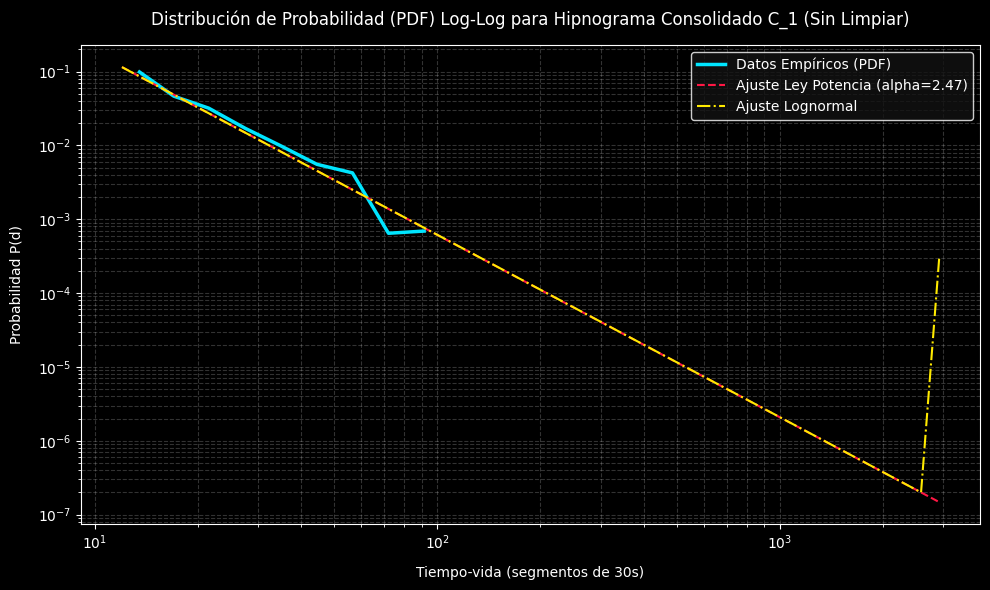

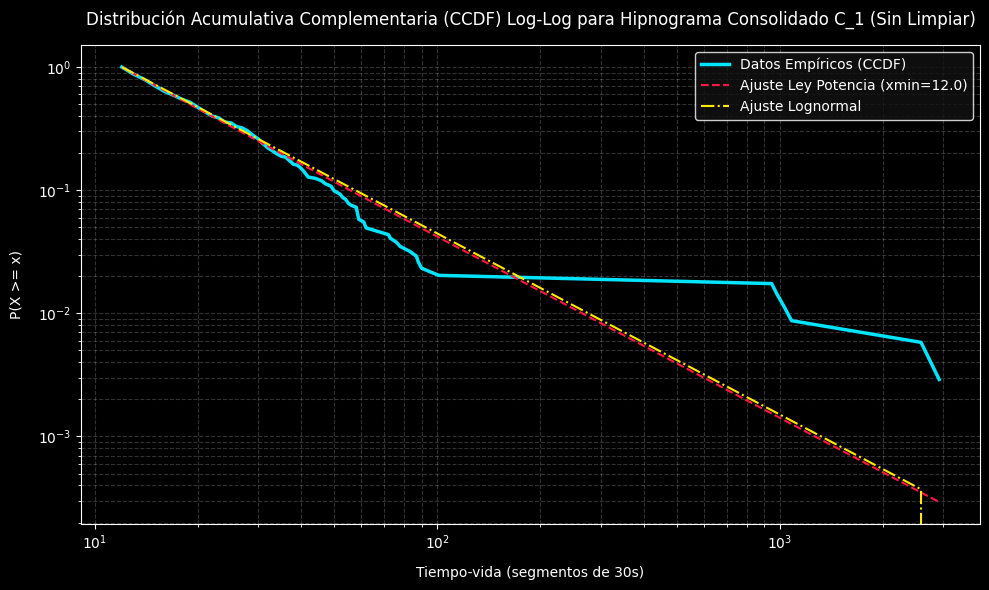


=== ANÁLISIS DE CLAUSET ET AL. PARA: Hipnograma Consolidado C_2 (Sin Limpiar) ===
Total de observaciones (lifetimes): 4561
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 60/60 [00:00<00:00, 878.90it/s]

  xmin óptimo calculado: 4.0
  Exponente alpha (mle): 2.3488
  Distancia KS mínima: 0.0235
  Comparación Power Law vs Lognormal:
    Log-Likelihood Ratio (R): 0.9852
    p-valor del test de razón: 0.3245
    -> Ninguna de las dos distribuciones es significativamente mejor que la otra.


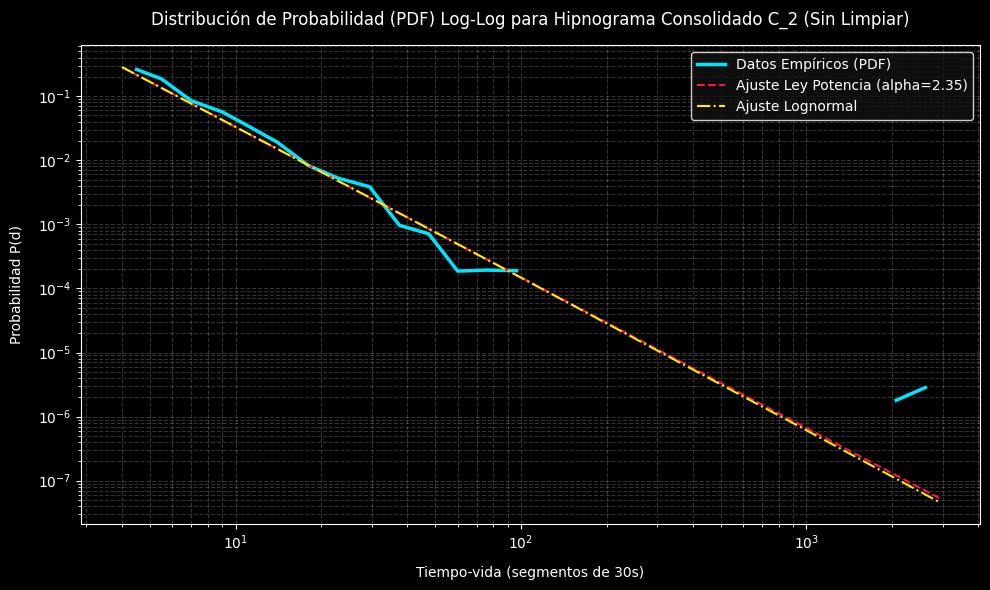

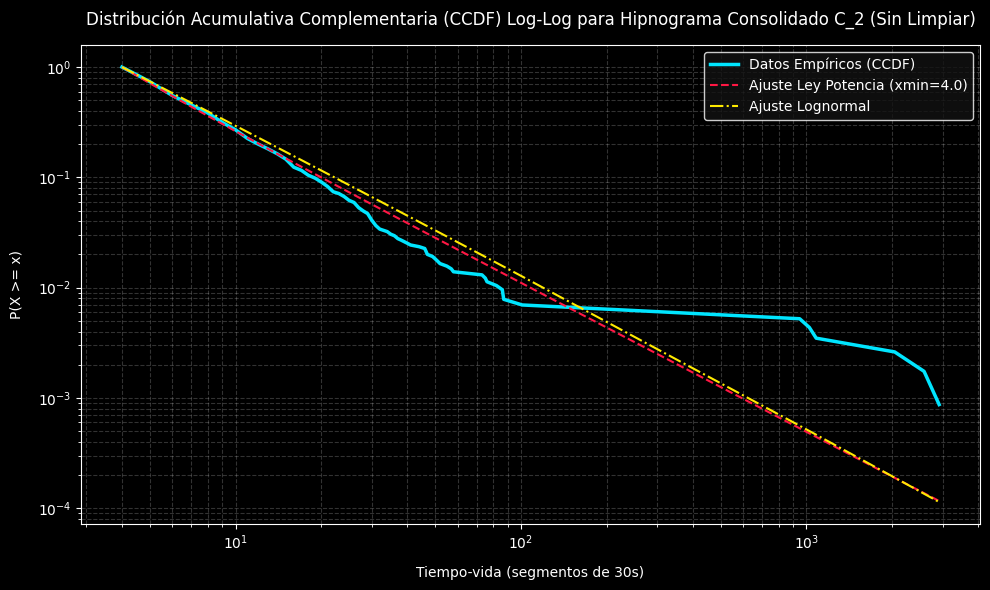

In [28]:
# Desactivamos temporalmente los warnings de ejecución y de la librería powerlaw
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    warnings.filterwarnings("ignore", message=".*No valid fits found.*")

    fit_sin_limpiar_C1 = aplicar_clauset_completo(hipnograma_1, "Hipnograma Consolidado C_1 (Sin Limpiar)")
    fit_sin_limpiar_C2 = aplicar_clauset_completo(hipnograma_2, "Hipnograma Consolidado C_2 (Sin Limpiar)")


### Seccion 26 Explicación Matemática y Metodológica (Clauset et al., 2009) y Aplicacion del Metodo CSN a los Hipnogramas Limpios

El método desarrollado por Aaron Clauset, Cosma Rohilla Shalizi y Mark Newman proporciona un marco estadístico riguroso para discernir si un conjunto de datos sigue una distribución de ley de potencia (Power Law).

### 1. Estimación de Parámetros

#### A. Estimación de $x_{\min}$ (Límite Inferior de la Cola)
No todos los datos siguen la ley de potencia, normalmente solo los valores mayores o iguales a un umbral $x_{\min}$ presentan este comportamiento. Clauset et al. proponen seleccionar $x_{\min}$ de forma no paramétrica minimizando la distancia de **Kolmogorov-Smirnov ($D$)** entre la distribución acumulativa de los datos reales ($S(x)$) y el modelo teórico ajustado ($P(x)$):

$$D = \max_{x \ge x_{\min}} |S(x) - P(x)|$$

Se realiza una búsqueda iterativa probando cada valor único del dataset como candidato a $x_{\min}$, y seleccionamos aquel que arroje la menor distancia $D$.

#### B. Estimación por Máxima Verosimilitud (MLE) de $\alpha$
Una vez seleccionado $x_{\min}$, el exponente de escala $\alpha$ se estima analíticamente para el caso continuo mediante:

$$\hat{\alpha} = 1 + n \left[ \sum_{i=1}^{n} \ln \frac{x_i}{x_{\min}} \right]^{-1}$$

Para variables discretas (como el número de segmentos de 30 segundos en nuestros hipnogramas), el estimador MLE se encuentra resolviendo numéricamente la relación implícita usando la función zeta de Hurwitz (Riemann) $\zeta(\alpha, x_{\min})$:

$$\frac{\zeta'(\alpha, x_{\min})}{\zeta(\alpha, x_{\min})} = -\frac{1}{n} \sum_{i=1}^{n} \ln x_i$$

---

### 2. Contraste de Hipótesis y Comparaciones

* **Test de Razón de Verosimilitud (Likelihood Ratio Test - LRT):** Compara directamente el ajuste de la ley de potencia frente a otra distribución (ej. Lognormal). Si la razón de log-verosimilitud $R > 0$ con un $p\text{-valor} < 0.05$, significa que la ley de potencia es estadísticamente superior.
* **Cálculo del p-valor por remuestreo (Monte Carlo):** Se generan miles de muestras sintéticas bajo la hipótesis nula, se reajustan bajo el mismo método y se compara su distancia $D$ con la empírica. Si $p \ge 0.1$, la hipótesis nula (ley de potencia) se considera una explicación plausible para los datos.

---

### 3. Explicación de los Gráficos Generados

1. **Distribución de Probabilidad (PDF) Log-Log:**
   * **Ejes:** Ambos ejes (eje X: Duración de la racha; eje Y: Probabilidad) están en escala logarítmica.
   * **Datos empíricos (Línea Azul):** Representa la frecuencia relativa real de cada duración. En escala log-log, una ley de potencia pura se visualiza como una línea recta decreciente.
   * **Ajuste de Ley de Potencia (Línea Roja):** Es la recta ideal estimada. Permite contrastar visualmente qué tan bien se alinean los datos empíricos a la tendencia lineal teórica a partir de $x_{\min}$.
   * **Ajuste Lognormal (Línea Verde):** Muestra el modelo alternativo ajustado a los datos.

2. **Función de Distribución Acumulativa Complementaria (CCDF) Log-Log:**
   * **Significado:** Grafica la probabilidad acumulada hacia la cola, es decir, $P(X \ge x)$.
   * **Ventaja:** La CCDF filtra gran parte del ruido estadístico inherente a las frecuencias individuales en las colas largas, ofreciendo una representación mucho más suave y confiable para evaluar la validez visual del ajuste.



=== ANÁLISIS DE CLAUSET ET AL. PARA: Hipnograma Consolidado C_1 ===
Total de observaciones (lifetimes): 3765
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 66/66 [00:00<00:00, 574.93it/s]

  xmin óptimo calculado: 11.0
  Exponente alpha (mle): 2.5696
  Distancia KS mínima: 0.0496
  Comparación Power Law vs Lognormal:
    Log-Likelihood Ratio (R): -2.9201
    p-valor del test de razón: 0.0035
    -> Lognormal es estadísticamente mejor que Ley de potencia.


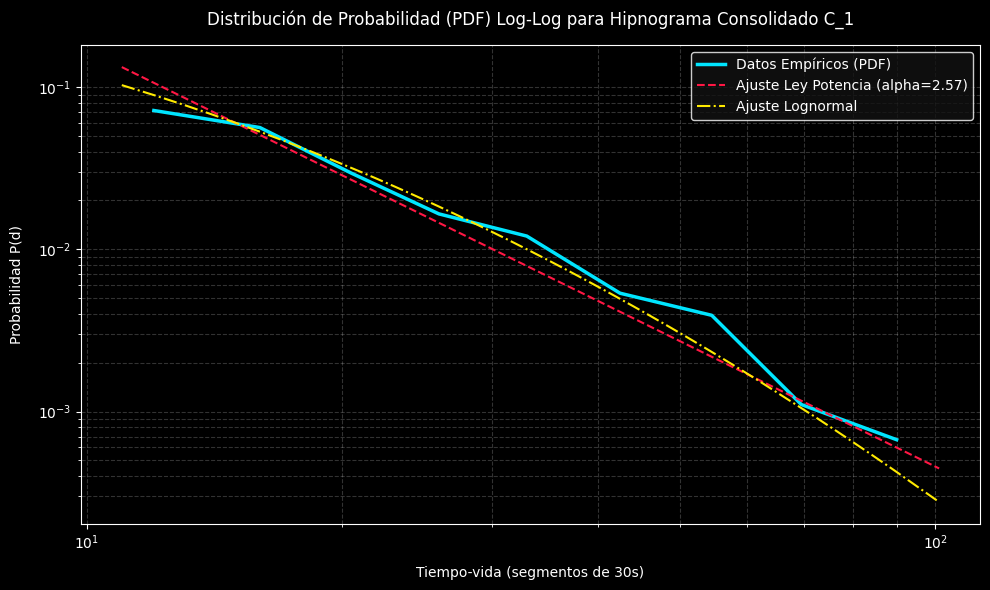

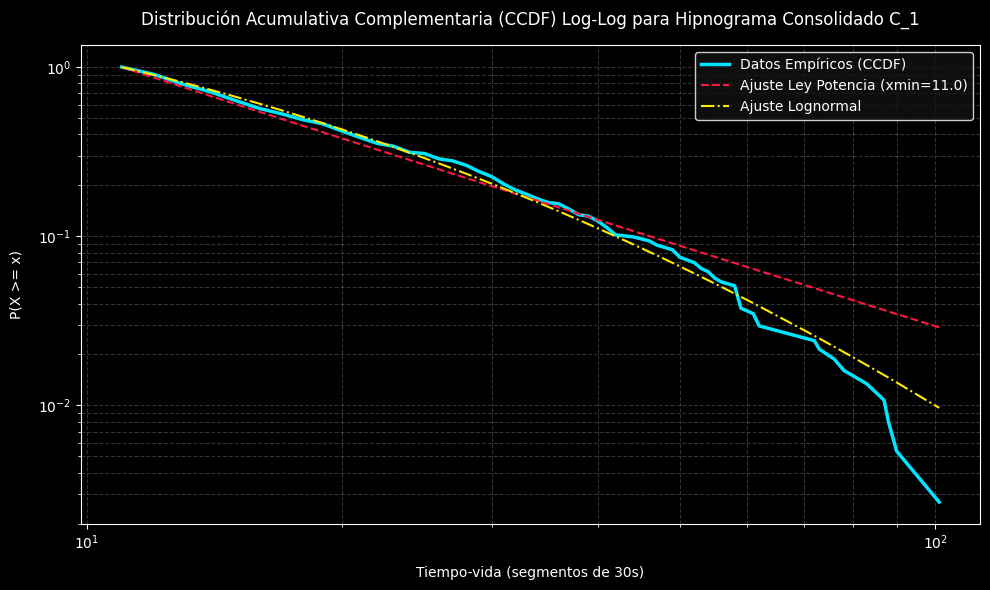


=== ANÁLISIS DE CLAUSET ET AL. PARA: Hipnograma Consolidado C_2 ===
Total de observaciones (lifetimes): 4561
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 54/54 [00:00<00:00, 515.25it/s]

  xmin óptimo calculado: 4.0
  Exponente alpha (mle): 2.4028
  Distancia KS mínima: 0.0334
  Comparación Power Law vs Lognormal:
    Log-Likelihood Ratio (R): -2.8255
    p-valor del test de razón: 0.0047
    -> Lognormal es estadísticamente mejor que Ley de potencia.


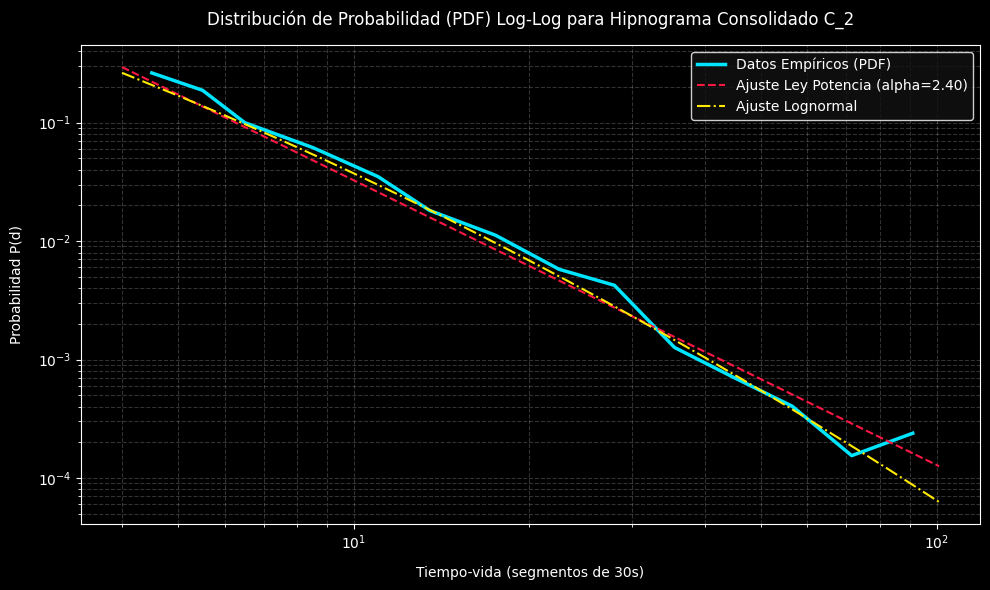

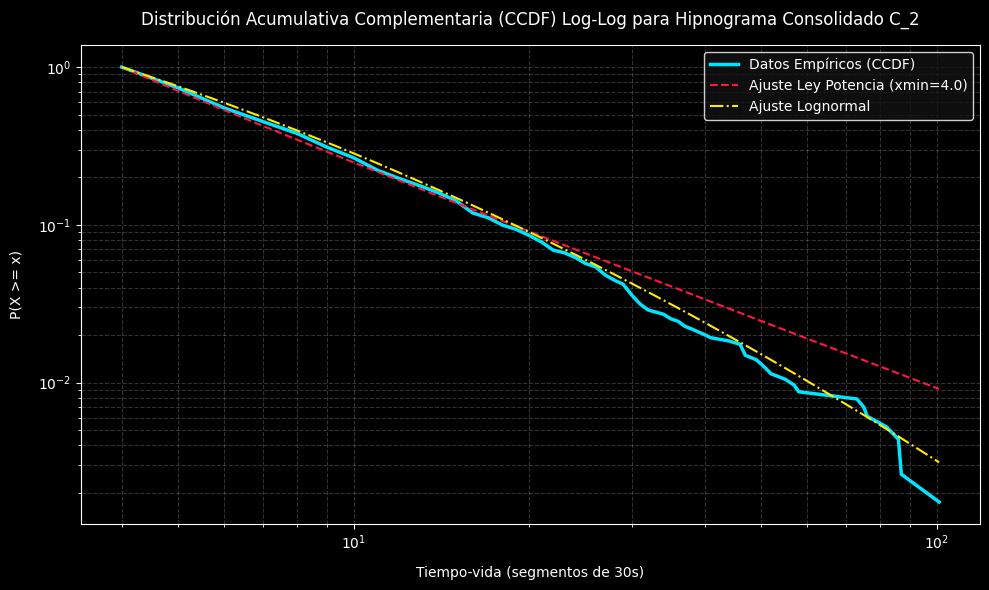

In [29]:
# Ejecuta todo el flujo analítico completo para las series limpias
fit_C1 = aplicar_clauset_completo(hipnograma_1_limpio, "Hipnograma Consolidado C_1")
fit_C2 = aplicar_clauset_completo(hipnograma_2_limpio, "Hipnograma Consolidado C_2")


#### Explicación Detallada Línea por Línea del Código (`aplicar_clauset_completo`)

A continuación se desglosa el comportamiento de cada sección del código implementado en la celda `HyaPgGyKPJ-I`:

### 1. Instalación e Importación de Librerías
* **`!pip install -q powerlaw`**:
  Instala de forma silenciosa (`-q`) la librería especializada `powerlaw` en el entorno actual de Colab.
* **`import numpy as np`**, **`import pandas as pd`**, **`import matplotlib.pyplot as plt`**:
  Carga las herramientas fundamentales para operaciones matemáticas rápidas (arrays), manipulación de datos en tablas y generación de gráficos respectivamente.
* **`import powerlaw`**:
  Importa la biblioteca que implementa el framework exacto de Clauset et al. (2009).

---

### 2. Extracción de los Tiempos-Vida (Lifetimes)
* **`cambios = np.r_[True, np.diff(np.asarray(seq)) != 0]`**:
  Calcula la diferencia entre elementos consecutivos de la serie del hipnograma (`np.diff`). Si la diferencia es distinta de cero (`!= 0`), indica un cambio de etapa. Se concatena un valor `True` al inicio (`np.r_`) para marcar el comienzo de la primera racha.
* **`grupos = np.cumsum(cambios)`**:
  Realiza una suma acumulativa del vector booleano anterior. Cada vez que hay un `True` (un cambio de racha), el contador numérico del grupo se incrementa, asignando una etiqueta de grupo única a cada racha consecutiva.
* **`_, duraciones = np.unique(grupos, return_counts=True)`**:
  Identifica cuántos elementos (segmentos de 30 segundos) pertenecen a cada grupo consecutivo, lo que equivale directamente a obtener la duración (lifetime) de cada racha.
* **`data = duraciones.astype(float)`**:
  Convierte el array de duraciones a formato punto flotante para asegurar la máxima precisión numérica durante los cálculos posteriores.

---

### 3. Ajuste del Modelo y Estimación de Parámetros
* **`fit = powerlaw.Fit(data, discrete=True, xmin=None)`**:
  Crea el objeto de ajuste principal. Le indicamos que los datos de entrada son discretos (`discrete=True`) porque medimos el tiempo en segmentos enteros. Al pasar `xmin=None`, ordenamos al algoritmo buscar automáticamente el umbral óptimo de corte ($x_{\min}$) que minimiza la distancia de Kolmogorov-Smirnov (KS).
* **`alpha = fit.power_law.alpha`**:
  Extrae el exponente de escala (parámetro de ley de potencia $\alpha$) calculado mediante estimación por máxima verosimilitud (MLE) a partir del umbral $x_{\min}$.
* **`xmin = fit.power_law.xmin`**:
  Obtiene el valor del límite inferior óptimo ($x_{\min}$) encontrado por el algoritmo.
* **`ks_distance = fit.power_law.D`**:
  Extrae la distancia mínima de Kolmogorov-Smirnov entre la distribución empírica de las colas y el modelo teórico.

---

### 4. Comparación de Distribuciones (LRT)
* **`R, p_value_ratio = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)`**:
  Calcula el test de razón de verosimilitud (Likelihood Ratio Test). Devuelve la métrica de dirección $R$ (si es positiva, favorece a la ley de potencia; si es negativa, a la lognormal) y el $p$-valor de significancia para ver si esa diferencia es estadísticamente real o fruto del azar.

---

### 5. Visualización Gráfica
* **`fig = fit.plot_pdf(color='b', linewidth=2, label='...')`**:
  Dibuja en escala log-log la función de densidad de probabilidad empírica (PDF) para todas las duraciones observadas.
* **`fit.power_law.plot_pdf(color='r', linestyle='--', ax=fig, ...)`**:
  Superpone sobre el mismo gráfico (`ax=fig`) la curva teórica del modelo de Ley de Potencia ajustado a partir del umbral $x_{\min}$.
* **`fit.lognormal.plot_pdf(color='g', linestyle='-.', ax=fig, ...)`**:
  Superpone en el mismo plano la curva del ajuste de distribución lognormal para fines comparativos.
* **`fit.plot_ccdf(...)`** / **`fit.power_law.plot_ccdf(...)`**:
  Repite el mismo procedimiento de dibujo pero calculando la Función de Distribución Acumulativa Complementaria (CCDF), la cual es mucho más limpia y estable visualmente para colas pesadas.



#### Guía Algorítmica Paso a Paso de la Implementación de Clauset et al. (2009)

A continuación, se describe la secuencia algorítmica exacta implementada en la función `aplicar_clauset_completo` para procesar los hipnogramas de sueño según el estándar metodológico riguroso para sistemas complejos y distribuciones de colas pesadas:

### Paso 1: Extracción de la Muestra de Tiempos-Vida (Lifetimes)
Para analizar la dinámica de las fases de sueño como un proceso de colas pesadas, primero debemos mapear la secuencia temporal discontinua a un conjunto de duraciones continuas o discretas denominadas rachas consecutivas:
1. **Detección de Fronteras de Estado:** Se calcula el operador de diferencia discreta de primer orden sobre la serie temporal de etapas con `np.diff`. Cualquier valor de diferencia distinto de cero representa un cambio de etapa fisiológica.
2. **Agrupamiento Consecutivo:** Mediante una suma acumulativa (`np.cumsum`) de estos puntos de cambio de estado, se genera un vector de etiquetas idénticas para cada segmento consecutivo que pertenece a la misma racha.
3. **Cálculo de Duraciones:** Usando la función `np.unique` con retorno de frecuencias (`return_counts=True`), el algoritmo determina cuántos segmentos temporales componen cada racha individual. Esta salida numérica se convierte a punto flotante (`float`) y se almacena en la variable de estudio $x$.

### Paso 2: Búsqueda del Límite de la Cola ($x_{\min}$) por Minimización de Kolmogorov-Smirnov
Una ley de potencia ideal rara vez describe todo el rango de observaciones; comúnmente solo rige a partir de un umbral inferior $x_{\min}$. En lugar de seleccionar este umbral de manera visual o arbitraria, la implementación automatiza su búsqueda:
1. **Candidatos a Umbral:** Se define un espacio de búsqueda que contiene cada valor único observado en el conjunto de datos de duraciones.
2. **Evaluación de Modelos Teóricos:** Para cada candidato $x_{c}$ en el espacio de búsqueda:
   * Se descartan temporalmente todas las observaciones menores a $x_{c}$.
   * Se ajusta por Máxima Verosimilitud (MLE) una distribución de ley de potencia discreta sobre los datos restantes $x \ge x_{c}$.
   * Se computa la distribución acumulativa teórica del ajuste ($P(x)$) y la acumulativa empírica real de la muestra ($S(x)$).
3. **Cálculo de la Distancia KS ($D$):** Se calcula la máxima discrepancia absoluta vertical entre ambas curvas acumulativas:
   $$D_c = \max_{x \ge x_c} |S(x) - P(x)|$$
4. **Selección del $x_{\min}$ Óptimo:** El algoritmo de `powerlaw.Fit` selecciona como $x_{\min}$ final el candidato que produce la menor distancia $D$ global, maximizando la concordancia entre los datos empíricos de la cola y el modelo lineal teórico.

### Paso 3: Estimación del Exponente de Escala (Alpha) por MLE
Con el valor de $x_{\min}$ óptimo ya definido:
1. **Ajuste Numérico Discreto:** El exponente de escala $\alpha$ de la ley de potencia $p(x) \propto x^{-\alpha}$ se aproxima utilizando el método de estimación por máxima verosimilitud para variables discretas. Debido a la naturaleza entera de los segmentos de racha de sueño, el algoritmo maximiza la función de log-verosimilitud usando la función zeta de Hurwitz:
   $$\mathcal{L}(\alpha) = -n \ln \zeta(\alpha, x_{\min}) - \alpha \sum_{i=1}^{n} \ln x_i$$
2. Se resuelve numéricamente la derivada respecto a $\alpha$ para hallar el punto donde la verosimilitud es máxima, reportando dicho exponente como `fit.power_law.alpha`.

### Paso 4: Contraste Riguroso frente a Distribuciones Alternativas
Para certificar si una ley de potencia es el modelo más representativo para las rachas de sueño, se realiza una prueba de razón de verosimilitudes (Likelihood Ratio Test) utilizando el estimador de Vuong:
1. Se ajusta un modelo alternativo clásico para colas pesadas: la distribución **Lognormal**.
2. Se calcula la razón del logaritmo de verosimilitud de ambos ajustes:
   $$\mathcal{R} = \ln \mathcal{L}_{\text{power_law}} - \ln \mathcal{L}_{\text{lognormal}}$$
3. **Dirección de la Evidencia (Signo de $\mathcal{R}$):** Un valor de $\mathcal{R} > 0$ indica que los datos son más verosímiles bajo la ley de potencia. Un valor de $\mathcal{R} < 0$ indica que el modelo lognormal describe mejor la cola de la distribución.
4. **Prueba de Hipótesis y Significancia ($p$-valor):** Se computa el $p$-valor de Vuong. Si $p < 0.05$, la ventaja del modelo ganador es estadísticamente significativa. Si $p \ge 0.05$, la fluctuación en la verosimilitud es ruidosa y ninguna distribución es estadísticamente superior a la otra.


##CONSOLIDADO GLOBAL

### Sección 26: Consolidado Global de Hipnogramas Limpios (`hipnograma_global`)

En esta sección creamos un único flujo temporal continuo unificando ambos evaluadores. Concatenamos secuencialmente `hipnograma_1_limpio` e `hipnograma_2_limpio` de modo que la serie del segundo clasificador comience inmediatamente al finalizar la del primero. Esto nos permite analizar las propiedades estadísticas globales y de escala sobre la totalidad de los datos limpios acumulados.

In [30]:
# Concatenación secuencial de los dos hipnogramas limpios
hipnograma_global = hipnograma_1_limpio + hipnograma_2_limpio

print(f"Longitud Hipnograma 1 Limpio: {len(hipnograma_1_limpio)} segmentos")
print(f"Longitud Hipnograma 2 Limpio: {len(hipnograma_2_limpio)} segmentos")
print(f"Longitud Hipnograma Global: {len(hipnograma_global)} segmentos")

Longitud Hipnograma 1 Limpio: 16939 segmentos
Longitud Hipnograma 2 Limpio: 15879 segmentos
Longitud Hipnograma Global: 32818 segmentos


### Visualización del Hipnograma Global

Graficamos el perfil temporal completo del nuevo `hipnograma_global` utilizando Plotly para mapear de forma interactiva la evolución de las etapas de sueño a lo largo de la serie concatenada.

In [31]:
tiempo_horas_global_limpio = np.arange(len(hipnograma_global)) * 30 / 3600

fig_global = go.Figure()
fig_global.add_trace(go.Scatter(
    x=tiempo_horas_global_limpio, y=hipnograma_global, mode='lines',
    line=dict(shape='hv', width=1, color='#9467bd'),
    name='Hipnograma Global',
    hovertext=[f"{v}: {ETAPAS[v]}" for v in hipnograma_global], hoverinfo='x+text',
))

fig_global.update_layout(
    template='plotly_dark', height=450,
    title_text='<b>Hipnograma Global (C_1 + C_2 Consolidado Secuencialmente)</b>',
    title_x=0.5, margin=dict(l=90, r=40, t=80, b=60),
    xaxis_title='Tiempo transcurrido acumulado (horas)',
    yaxis_title='Etapa de Sueño'
)
fig_global.update_yaxes(
    tickvals=list(range(8)),
    ticktext=[f"{j}: {n}" for j, n in enumerate(ETAPAS)],
    range=[-0.5, 7.5]
)
fig_global.show()

In [32]:


# 1. Calcular la matriz de conteo de transiciones absolutas
M_global = matriz_transiciones(hipnograma_global)

# 2. Calcular la matriz de probabilidades de transición (normalizando filas)
fila_suma = M_global.sum(axis=1, keepdims=True)
P_global = np.divide(M_global, fila_suma, out=np.zeros_like(M_global, dtype=float), where=fila_suma != 0)

etiquetas = [f"{i}: {n}" for i, n in enumerate(ETAPAS)]

# 3. Graficar Matriz de Conteo Absoluto
fig_conteo = go.Figure(go.Heatmap(
    z=M_global,
    x=etiquetas,
    y=etiquetas,
    colorscale='Cividis',
    text=M_global,
    texttemplate='%{text}',
    textfont=dict(size=10, color='white'),
    hovertemplate='Origen: %{y}<br>Destino: %{x}<br>Conteo Absoluto: %{z}<extra></extra>',
))
fig_conteo.update_layout(
    template='plotly_dark',
    title='<b>Matriz de Transición de Conteos Absolutos (Hipnograma Global)</b>',
    xaxis_title='Etapa destino (t + 1)',
    yaxis_title='Etapa origen (t)',
    height=600, width=700
)
fig_conteo.update_yaxes(autorange='reversed')
fig_conteo.show()

# 4. Graficar Matriz de Probabilidades (con la paleta de visión térmica 'Jet')
fig_prob = go.Figure(go.Heatmap(
    z=P_global,
    x=etiquetas,
    y=etiquetas,
    colorscale='Cividis',
    text=np.round(P_global, 2),
    texttemplate='%{text}',
    textfont=dict(size=10, color='white'),
    hovertemplate='Origen: %{y}<br>Destino: %{x}<br>P(Destino | Origen): %{z:.3f}<extra></extra>',
    colorbar=dict(title='Probabilidad')
))
fig_prob.update_layout(
    template='plotly_dark',
    title='<b>Matriz de Probabilidades de Transición P(Destino | Origen) (Hipnograma Global)</b>',
    xaxis_title='Etapa destino (t + 1)',
    yaxis_title='Etapa origen (t)',
    height=600, width=750
)
fig_prob.update_yaxes(autorange='reversed')
fig_prob.show()

In [33]:
print("Calculando medidas de Teoría de la Información y Autocorrelación para el Hipnograma Global...")

# Convertimos el hipnograma global a un array de numpy para cálculos eficientes
seq_global = np.asarray(hipnograma_global)

# Calculamos las métricas para el hipnograma global bajo los retardos del 1 al 300
conj_valores_global = []
cond_valores_global = []
mi_valores_global = []
autocorr_valores_global = []

for t in taus:
    # 1. Teoría de la información
    h_xy, h_y_x, i_xy = calcular_medidas_informacion(seq_global, t)
    conj_valores_global.append(h_xy)
    cond_valores_global.append(h_y_x)
    mi_valores_global.append(i_xy)

    # 2. Autocorrelación lineal (Pearson) entre X_t y X_{t+t}
    x_t = seq_global[:-t]
    x_tau = seq_global[t:]
    if len(x_t) > 1 and np.std(x_t) > 0 and np.std(x_tau) > 0:
        r_coef = np.corrcoef(x_t, x_tau)[0, 1]
    else:
        r_coef = 0.0
    autocorr_valores_global.append(r_coef)

# Crear subplots interactivos de Plotly para el análisis global (4 filas, 2 columnas)
# Columna 1: Escala Lineal | Columna 2: Escala Log-Log
fig_info_global = make_subplots(
    rows=4, cols=2,
    shared_xaxes=False,
    horizontal_spacing=0.1,
    vertical_spacing=0.06,
    subplot_titles=(
        '<b>H(X_t, X_{t+τ}) — Lineal</b>', '<b>H(X_t, X_{t+τ}) — Log-Log</b>',
        '<b>H(X_{t+τ} | X_t) — Lineal</b>', '<b>H(X_{t+τ} | X_t) — Log-Log</b>',
        '<b>I(X_t ; X_{t+τ}) — Lineal</b>', '<b>I(X_t ; X_{t+τ}) — Log-Log</b>',
        '<b>Autocorrelación — Lineal</b>', '<b>Autocorrelación (Abs) — Log-Log</b>'
    )
)

# --- ENTROPÍA CONJUNTA (Fila 1) ---
fig_info_global.add_trace(go.Scatter(
    x=taus, y=conj_valores_global,
    mode='lines', name='Entropía Conjunta (Lin)',
    line=dict(width=2.5, color='#00E5FF'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t, X_t+τ): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=1, col=1)

fig_info_global.add_trace(go.Scatter(
    x=taus, y=conj_valores_global,
    mode='lines', name='Entropía Conjunta (Log)',
    line=dict(width=2.5, color='#00E5FF', dash='dash'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t, X_t+τ): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=1, col=2)

# --- ENTROPÍA CONDICIONAL (Fila 2) ---
fig_info_global.add_trace(go.Scatter(
    x=taus, y=cond_valores_global,
    mode='lines', name='Entropía Condicional (Lin)',
    line=dict(width=2.5, color='#FFEA00'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t+τ|X_t): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=2, col=1)

fig_info_global.add_trace(go.Scatter(
    x=taus, y=cond_valores_global,
    mode='lines', name='Entropía Condicional (Log)',
    line=dict(width=2.5, color='#FFEA00', dash='dash'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>H(X_t+τ|X_t): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=2, col=2)

# --- INFORMACIÓN MUTUA (Fila 3) ---
fig_info_global.add_trace(go.Scatter(
    x=taus, y=mi_valores_global,
    mode='lines', name='Información Mutua (Lin)',
    line=dict(width=2.5, color='#9467bd'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>I(X_t; X_t+τ): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=3, col=1)

fig_info_global.add_trace(go.Scatter(
    x=taus, y=mi_valores_global,
    mode='lines', name='Información Mutua (Log)',
    line=dict(width=2.5, color='#9467bd', dash='dash'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>I(X_t; X_t+τ): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=3, col=2)

# --- AUTOCORRELACIÓN (Fila 4) ---
fig_info_global.add_trace(go.Scatter(
    x=taus, y=autocorr_valores_global,
    mode='lines', name='Autocorrelación (Lin)',
    line=dict(width=2.5, color='#FF5722'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>R(τ): %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=4, col=1)

# Para log-log en correlación, aplicamos valor absoluto para evitar indeterminaciones por coeficientes negativos
fig_info_global.add_trace(go.Scatter(
    x=taus, y=np.abs(autocorr_valores_global),
    mode='lines', name='Autocorrelación (Log)',
    line=dict(width=2.5, color='#FF5722', dash='dash'),
    hovertemplate='Lag: %{x} segs (%{customdata:.1f} min)<br>|R(τ)|: %{y:.4f}<extra></extra>',
    customdata=taus * 30 / 60
), row=4, col=2)

# Resaltar la franja del ciclo ultradiano fisiológico de ~90 min (160-200 segmentos) en la columna Lineal (Columna 1)
for r in range(1, 5):
    fig_info_global.add_vrect(
        x0=160, x1=200,
        fillcolor="rgba(255, 234, 0, 0.08)",
        line_width=0,
        annotation_text="Ciclo Ultradiano (~90 min)" if r == 1 else "",
        annotation_position="top",
        annotation_font=dict(color="#FFEA00", size=9),
        row=r, col=1
    )

# Configurar los ejes para la columna Log-Log (Columna 2)
for r in range(1, 5):
    fig_info_global.update_xaxes(type='log', row=r, col=2)
    fig_info_global.update_yaxes(type='log', row=r, col=2)

# Ajustes de diseño global
fig_info_global.update_layout(
    template='plotly_dark',
    title='<b>Análisis Global: Medidas de Teoría de la Información y Autocorrelación (Lineal vs Log-Log)</b>',
    height=1400,
    showlegend=False,
    margin=dict(r=50, t=100, b=80)
)

# Títulos de ejes
for c in (1, 2):
    fig_info_global.update_xaxes(title_text='Retardo τ (segmentos de 30 s)', row=4, col=c)

for r in range(1, 5):
    fig_info_global.update_yaxes(title_text='Bits', row=r, col=1)
    fig_info_global.update_yaxes(title_text='Bits (log)', row=r, col=2)

# Personalizar etiquetas de eje Y específicos para autocorrelación (Fila 4)
fig_info_global.update_yaxes(title_text='Coef. R', row=4, col=1)
fig_info_global.update_yaxes(title_text='|Coef. R| (log)', row=4, col=2)

fig_info_global.show()

Calculando medidas de Teoría de la Información y Autocorrelación para el Hipnograma Global...


### Distribución Empírica de Tiempos-Vida del Hipnograma Global

Extraemos los lifetimes de la nueva serie temporal y graficamos su distribución de probabilidad empírica $P(d)$ en escala logarítmica (log-log) para caracterizar visualmente el decaimiento de las colas.

In [34]:


dur_global = calcular_lifetimes(hipnograma_global)['duracion'].tolist()
x_g, p_g = probabilidades_lifetimes(dur_global)

# Creamos subplots: 1 fila, 2 columnas
fig_dist_global = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        '<b>Escala Log-Log</b>',
        '<b>Escala Lineal</b>'
    )
)

# Gráfica en escala Log-Log (Columna 1)
fig_dist_global.add_trace(go.Scatter(
    x=x_g, y=p_g, mode='markers',
    name='Hipnograma Global (Log)',
    marker=dict(size=8, color='#9467bd', line=dict(width=0.5, color='white')),
    hovertemplate='d = %{x}<br>P(d) = %{y:.2e}<extra></extra>'
), row=1, col=1)

# Gráfica en escala Lineal (Columna 2)
fig_dist_global.add_trace(go.Scatter(
    x=x_g, y=p_g, mode='markers+lines',
    name='Hipnograma Global (Lin)',
    marker=dict(size=6, color='#2ca02c', line=dict(width=0.5, color='white')),
    line=dict(width=1, dash='dot'),
    hovertemplate='d = %{x}<br>P(d) = %{y:.4f}<extra></extra>'
), row=1, col=2)

# Configuración de ejes y diseño general
fig_dist_global.update_layout(
    template='plotly_dark',
    title_text='<b>Distribución de Probabilidad de Tiempos-Vida (Hipnograma Global)</b>',
    title_x=0.5,
    height=550, width=1100,
    showlegend=False
)

# Ejes para escala Log-Log
fig_dist_global.update_xaxes(title_text='Tiempo-vida d (segmentos)', type='log', row=1, col=1)
fig_dist_global.update_yaxes(title_text='Probabilidad P(d)', type='log', row=1, col=1)

# Ejes para escala Lineal
fig_dist_global.update_xaxes(title_text='Tiempo-vida d (segmentos)', row=1, col=2)
fig_dist_global.update_yaxes(title_text='Probabilidad P(d)', row=1, col=2)

fig_dist_global.show()

### Aplicación del Método de Clauset et al. (CSN) al Hipnograma Global

Sometemos los tiempos-vida del `hipnograma_global` al framework analítico estricto de Clauset. Esto estimará el umbral inferior óptimo $x_{\min}$, el exponente de escala $\alpha$, y contrastará formalmente el ajuste de la Ley de Potencia frente al modelo alternativo Lognormal.


=== ANÁLISIS DE CLAUSET ET AL. PARA: Hipnograma Global (Consolidado C1 + C2) ===
Total de observaciones (lifetimes): 8326
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 70/70 [00:00<00:00, 450.13it/s]

  xmin óptimo calculado: 4.0
  Exponente alpha (mle): 2.2451
  Distancia KS mínima: 0.0425
  Comparación Power Law vs Lognormal:
    Log-Likelihood Ratio (R): -5.5855
    p-valor del test de razón: 0.0000
    -> Lognormal es estadísticamente mejor que Ley de potencia.


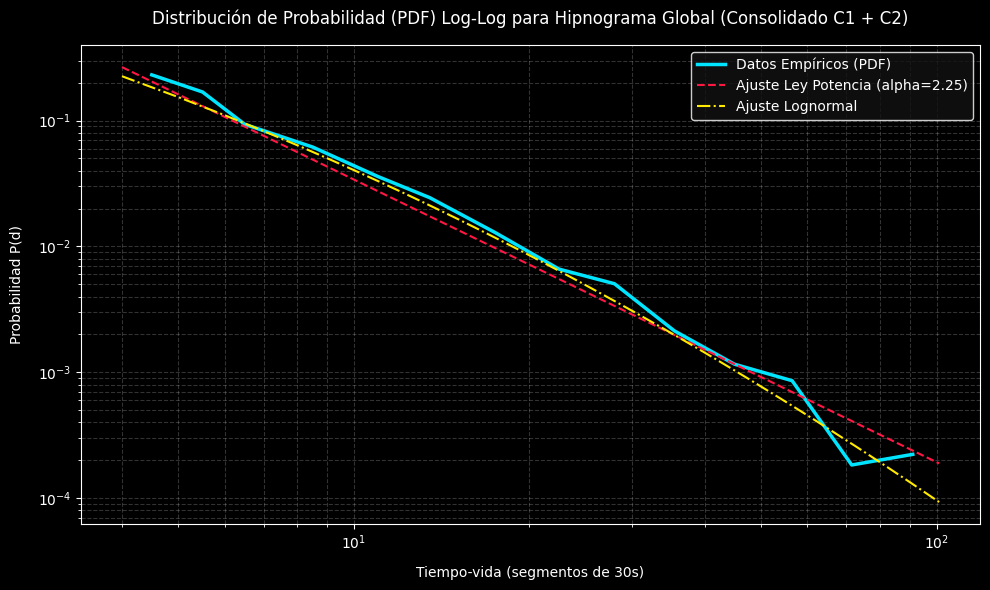

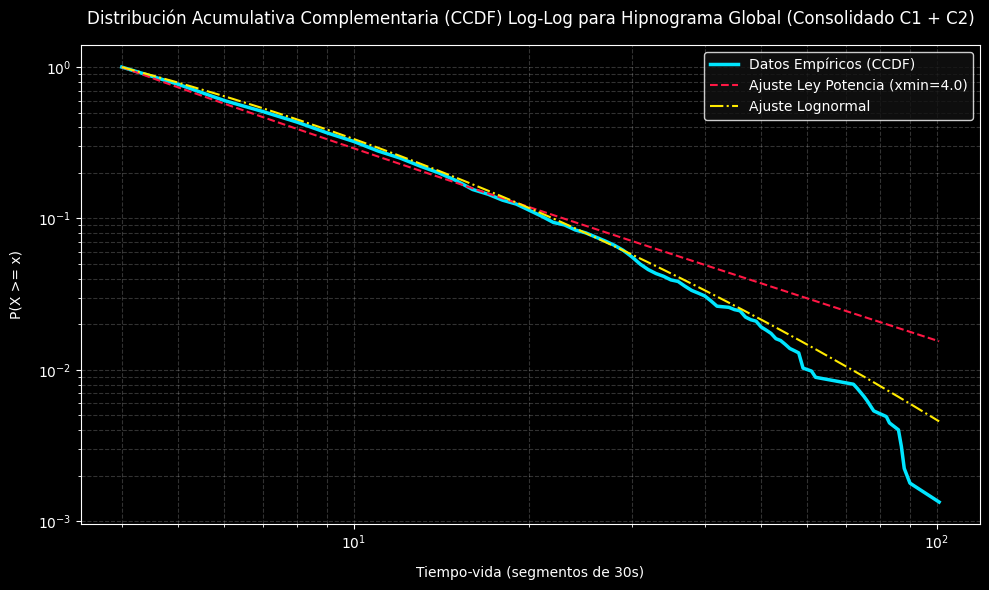

In [35]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    warnings.filterwarnings("ignore", message=".*No valid fits found.*")

    fit_global = aplicar_clauset_completo(hipnograma_global, "Hipnograma Global (Consolidado C1 + C2)")